# 1. Титульный лист

**Лабораторная работа № 4. MLOps**  
**Вариант 2. Сервис фильтрации SMS-спама**

Выполнил: Бикмухаметов Таир  
Группа: АВТ-314  


Новосибирск, 2026

Отчёт содержит выполненные ячейки, фактические идентификаторы MLflow, метрики,
выводы Docker и скриншоты реальных страниц.

## 2. Цель работы и постановка задачи

Освоить воспроизводимый цикл ML: подготовку данных, учёт и сравнение экспериментов
в MLflow, Model Registry и aliases, экспорт модели, API, Docker, обновление, откат
и Docker Compose с healthcheck.

Индивидуальная задача: по тексту SMS определить `ham` (обычное сообщение) или `spam`.
Исследуются `TF-IDF + MultinomialNB` с изменением `alpha` и
`TF-IDF + LogisticRegression` с изменением `C`. Основной критерий — **F1 для spam**;
дополнительно сравниваются precision и recall для spam. `spam=1`, `ham=0`.

Правило выбора задаётся до итогового тестирования: максимум validation F1; при равенстве —
максимум precision, далее порядок конфигураций в исходном коде. Порог 0,5 фиксирован.
Test не используется для изменения гиперпараметров или порога.

In [1]:
from pathlib import Path
import os
import sys
import json
import subprocess
import importlib.metadata

candidates = [Path.cwd(), Path.cwd() / 'lab4']
ROOT = next((p.resolve() for p in candidates if (p / 'sms_mlops/train.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Откройте ноутбук из lab4 или корня репозитория')
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.runtime/matplotlib'))

import pandas as pd
import numpy as np
from IPython.display import display, Markdown, Image
from sms_mlops.common import read_json, sha256, MODEL_NAME

def table(frame):
    display(frame.style.format(precision=6).set_properties(**{'text-align': 'left'}))

def screenshot(name, caption):
    path = ROOT / 'screenshots' / name
    if path.exists():
        display(Markdown(caption))
        display(Image(filename=str(path), width=1200))
    else:
        display(Markdown('Скриншот ещё не снят: `' + name + '`.'))

print('Каталог проекта:', ROOT)
print('Интерпретатор:', sys.executable)
print('Python:', sys.version.split()[0])

Каталог проекта: /home/tair/NETI/AI/lab4
Интерпретатор: /home/tair/NETI/AI/lab4/.venv/bin/python
Python: 3.12.3


## 3. Набор данных, подготовка и разбиение

Источник: [SMS Spam Collection, UCI](https://archive.ics.uci.edu/dataset/228/sms+spam+collection),
Almeida и Hidalgo, DOI [10.24432/C5CC84](https://doi.org/10.24432/C5CC84), лицензия CC BY 4.0.
Признак — исходная строка `text`, цель — метка `label`.
Идентификатор исходной строки `row_id` используется только для воспроизведения разбиения.

Оригинальный TSV читается разделением по **первой табуляции**, без CSV-интерпретации кавычек.
Пропуски, пустые тексты и неизвестные метки проверяются явно. Дубликаты определяются по
NFKC-нормализации, `casefold` и свёртке пробелов; сохраняется первое сообщение.
Группы с противоречащими метками исключаются полностью. Эта нормализация служит
только для проверки повторов, в классификатор передаётся исходный текст.
Решения об исключении сохранены в `data/excluded.csv`.

После очистки выполняется стратифицированное разбиение примерно 60/20/20 при `random_state=42`.
`data/splits.json` хранит точные исходные `row_id` и SHA-256 исходного файла.
Множества строк и хешей сообщений попарно не пересекаются. Близкие по смыслу шаблоны
могут оставаться — удаление повторов не решает проблему всех разновидностей похожих SMS.

TF-IDF обучается только внутри Pipeline на train. Validation и test преобразуются
уже обученным векторизатором. Англоязычный исторический корпус не даёт оснований
утверждать такое же качество на современных русскоязычных SMS.

In [2]:
from sms_mlops.data import prepare_data
frames, dataset = prepare_data()
display(pd.DataFrame([
    {'этап': 'Исходный файл', 'сообщений': dataset['raw_rows'], **dataset['raw_classes']},
    {'этап': 'После очистки', 'сообщений': dataset['clean_rows'], **dataset['clean_classes']},
]))
display(pd.DataFrame(dataset['splits']).T)
print('Исключено:', dataset['excluded_rows'])
print('Групп с противоречивыми метками:', dataset['conflicting_hashes'])
print('SHA-256 исходного файла:', dataset['raw_sha256'])
print('SHA-256 разбиения:', dataset['split_sha256'])
assert sha256(ROOT / 'data/raw/SMSSpamCollection') == dataset['raw_sha256']
assert all(set(frames[a].text_hash).isdisjoint(frames[b].text_hash)
           for a, b in [('train', 'validation'), ('train', 'test'), ('validation', 'test')])

,этап,сообщений,ham,spam
0,Исходный файл,5574,4827,747
1,После очистки,5159,4517,642


,rows,ham,spam
train,3095,2710,385
validation,1032,903,129
test,1032,904,128


Исключено: 415
Групп с противоречивыми метками: 0
SHA-256 исходного файла: 7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d
SHA-256 разбиения: c7c7f9c6bd2b5ab276809d4b7b134446449498cda7385b9e78e99e8fea279c5b


Набор несбалансирован: обычных сообщений значительно больше. Поэтому accuracy
может быть высокой даже при пропуске значительной части спама.
Precision для spam = TP/(TP+FP): насколько редко обычная SMS блокируется ошибочно.
Recall = TP/(TP+FN): какую долю спама обнаруживает модель.
F1 = 2PR/(P+R) учитывает оба вида ошибок.

## 4. Окружение, зависимости и структура проекта

Рабочая среда — Ubuntu 24.04 под WSL 2, Python 3.12, Docker Desktop с интеграцией WSL.
Для этой реализации зафиксированы и проверены версии ниже. Они отличаются от версий
учебного примера в PDF: код и API MLflow соответствуют именно установленной версии.
SQLAlchemy 2.0.44 закреплена явно: версия 2.1.8 оказалась несовместимой с MLflow 2.22.2.

`requirements.in` содержит прямые зависимости, `requirements.txt` — полный снимок,
`requirements-runtime.txt` — транзитивные зависимости только API и инференса.
В образ не включаются MLflow, Jupyter и исходные данные. Векторизатор и классификатор
имеют одинаковую версию scikit-learn при обучении и обслуживании.

In [3]:
packages = ['mlflow', 'sqlalchemy', 'scikit-learn', 'numpy', 'scipy', 'pandas',
            'fastapi', 'pydantic', 'uvicorn', 'joblib', 'nbconvert']
display(pd.DataFrame({'пакет': packages,
                      'версия': [importlib.metadata.version(p) for p in packages]}))
checked = subprocess.run([sys.executable, '-m', 'pip', 'check'], text=True, capture_output=True)
print(checked.stdout.strip())
assert checked.returncode == 0, checked.stderr
print((ROOT / 'compose.yaml').read_text())

,пакет,версия
0,mlflow,2.22.2
1,sqlalchemy,2.0.44
2,scikit-learn,1.6.1
3,numpy,2.2.6
4,scipy,1.15.3
5,pandas,2.2.3
6,fastapi,0.115.12
7,pydantic,2.11.5
8,uvicorn,0.34.2
9,joblib,1.6.0


No broken requirements found.
name: lab4-sms-spam
services:
  api:
    image: sms-spam:${MODEL_RELEASE:-v1}
    build:
      context: .
      args:
        MODEL_RELEASE: ${MODEL_RELEASE:-v1}
    ports:
      - "127.0.0.1:${API_PORT:-8000}:8000"
    restart: unless-stopped
    healthcheck:
      test: ["CMD", "python", "-c", "import urllib.request; urllib.request.urlopen('http://127.0.0.1:8000/health', timeout=2)"]
      interval: 5s
      timeout: 3s
      retries: 5
      start_period: 10s



```text
lab4/
  lab4_mlops.ipynb               выполненный отчёт
  README.md                     запуск под WSL
  sms_mlops/                    данные, обучение, API, проверки, Docker-сценарий
  scripts/                      генерация отчёта, lock-файлов, скриншотов
  tests/                        контракт API и контроль целостности модели
  data/raw/                     неизменённый оригинал UCI и описание
  data/clean.csv, excluded.csv   данные и журнал очистки
  data/splits.json              идентификаторы train/validation/test
  mlflow-data/mlflow.db          настоящая SQLite-база Tracking и Registry
  mlflow-data/artifacts/         Pipeline, signature, примеры, код, графики
  models/v1/, models/v2/         экспортированные Pipeline и metadata.json
  results/                      CSV, JSON, графики и протоколы проверок
  screenshots/                  реальные скриншоты браузера
  examples/                     корректные и некорректные JSON-запросы
  requirements*.in, *.txt        прямые и полные зависимости
  Dockerfile, compose.yaml, .dockerignore
```

## 5. Последовательность выполнения

Команды выполняются в bash из `lab4`. Docker переустанавливать не требуется.
В Docker Desktop должны быть запущен Linux engine и включена
Settings → Resources → WSL Integration → Ubuntu.

```bash
cd /home/tair/NETI/AI/lab4
python3 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements.txt
python -m pip check
docker version
docker compose version
python -m sms_mlops.train
python -m sms_mlops.verify
python -m pytest -q
python -m sms_mlops.docker_demo --require
```

Обучение пишет в SQLite непосредственно; отдельный работающий сервер для этого не нужен.
Для просмотра тех же данных в браузере запустить в другом терминале:

```bash
source .venv/bin/activate
mlflow server --backend-store-uri sqlite:///mlflow-data/mlflow.db \
  --default-artifact-root ./mlflow-data/artifacts --no-serve-artifacts \
  --host 127.0.0.1 --port 5000 --workers 1
```

Открыть <http://127.0.0.1:5000>. API обслуживается на <http://127.0.0.1:8000/docs>.
Ниже ноутбук использует сохранённые запуски. Если результатов ещё нет,
`train.run()` создаёт шесть экспериментов; `--force` создаёт **новые** run и номера Registry.

Используются сохранённые результаты. Для новых запусков: --force.
Проверено завершённых экспериментов: 6


**Рисунок 1. Настоящие шесть запусков в MLflow.**

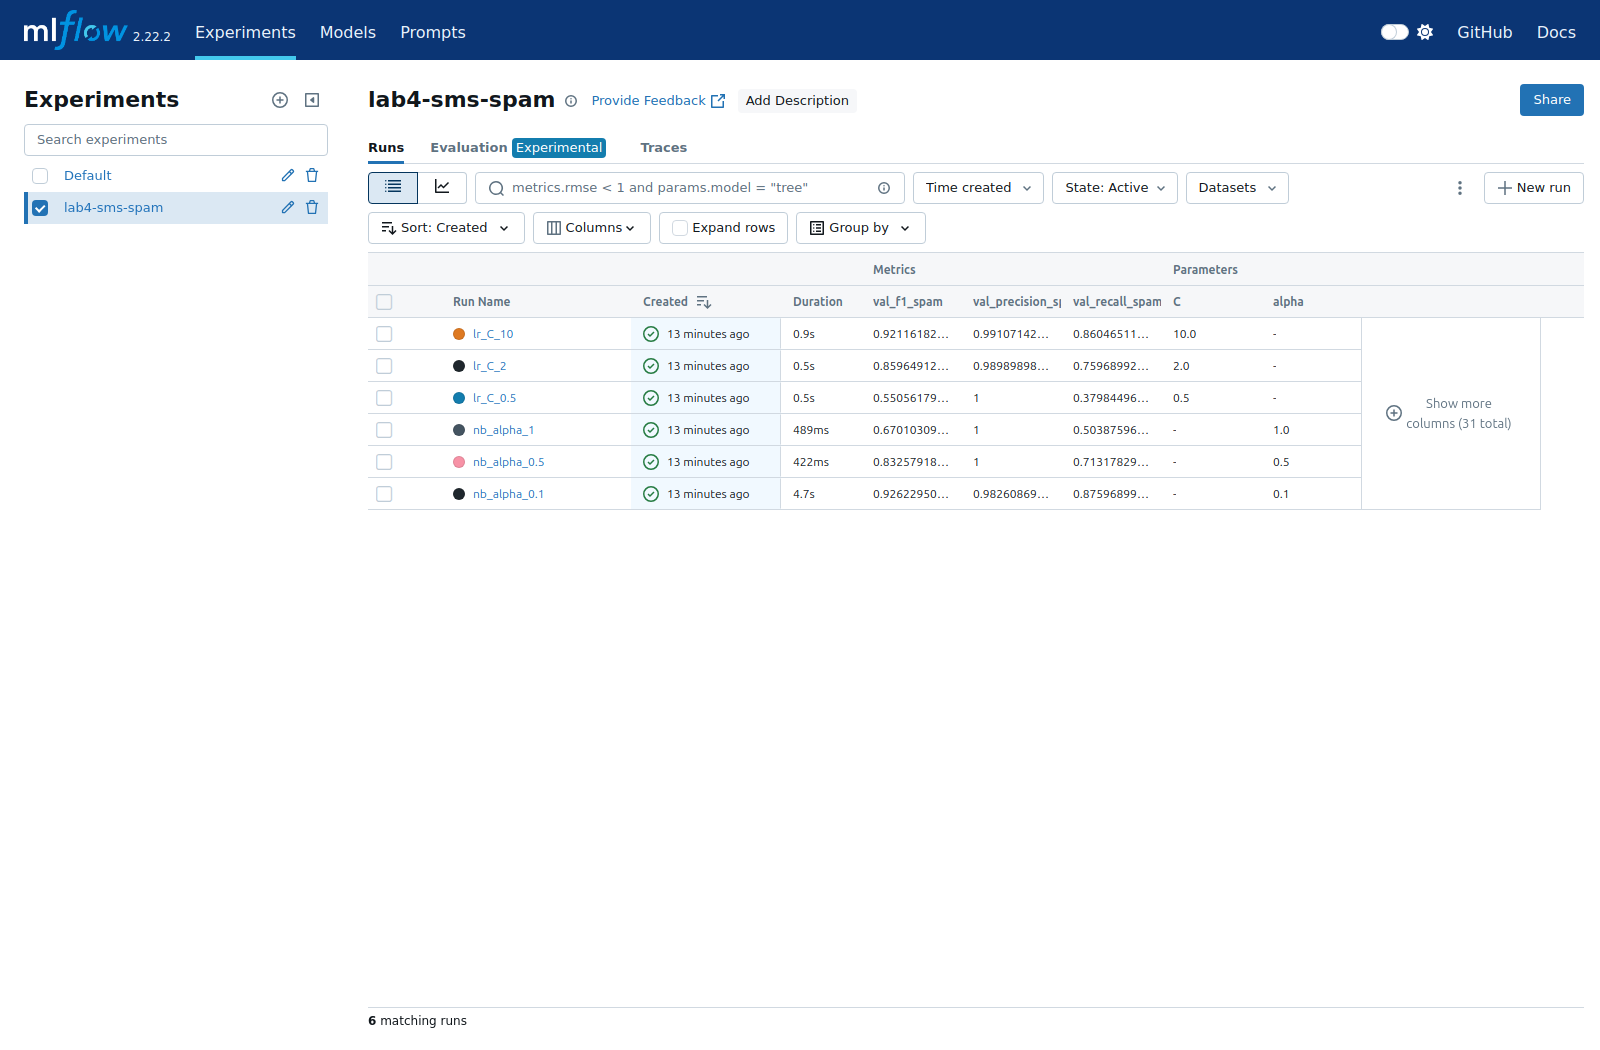

In [4]:
from sms_mlops.train import run, setup_tracking
summary = run()
client, experiment_id = setup_tracking()
experiments = pd.read_csv(ROOT / 'results/experiments.csv')
for run_id in experiments.run_id:
    assert client.get_run(run_id).info.status == 'FINISHED'
print('Проверено завершённых экспериментов:', len(experiments))
screenshot('01_mlflow_experiments.png', '**Рисунок 1. Настоящие шесть запусков в MLflow.**')

## 6. Сравнение экспериментов

Во всех опытах: word TF-IDF, униграммы и биграммы, `max_features=20000`,
`min_df=1`, `sublinear_tf=True`, `lowercase=True`, L2-нормировка.
MultinomialNB исследуется при `alpha ∈ {0.1, 0.5, 1}`;
LogisticRegression — при `C ∈ {0.5, 2, 10}`, `solver=liblinear`, `max_iter=2000`.
Для всех моделей используются одни и те же train и validation.

В каждом run сохранены параметры, seed, размеры выборок, четыре validation-метрики,
время обучения, размер словаря, теги варианта и контрольных сумм, входные datasets,
матрица ошибок, разбиение, исходный код, зависимости и MLflow-модель с signature/input_example.
Только после выбора чемпиону дополнительно записываются итоговые test-метрики.

,algorithm,parameter,value,val_f1_spam,val_precision_spam,val_recall_spam,val_accuracy,fit_seconds,run_id
0,MultinomialNB,alpha,0.100000,0.926230,0.982609,0.875969,0.982558,0.099339,4f7499ea175841c5a006088d92de6714
5,LogisticRegression,C,10.000000,0.921162,0.991071,0.860465,0.981589,0.563560,cd9cab5f394d490a9600eea8e5c0dfd2
4,LogisticRegression,C,2.000000,0.859649,0.989899,0.759690,0.968992,0.162894,0b868d7901f14dd88c9bb7dc5362f41f
1,MultinomialNB,alpha,0.500000,0.832579,1.000000,0.713178,0.964147,0.120266,0e234ea27f964c91abaf567432322b43
2,MultinomialNB,alpha,1.000000,0.670103,1.000000,0.503876,0.937984,0.142314,6b6bb00ba94043708a6fdbd8685ad6eb
3,LogisticRegression,C,0.500000,0.550562,1.000000,0.379845,0.922481,0.186974,d4f0c1ebfeb341739b16ea82e9f902b3


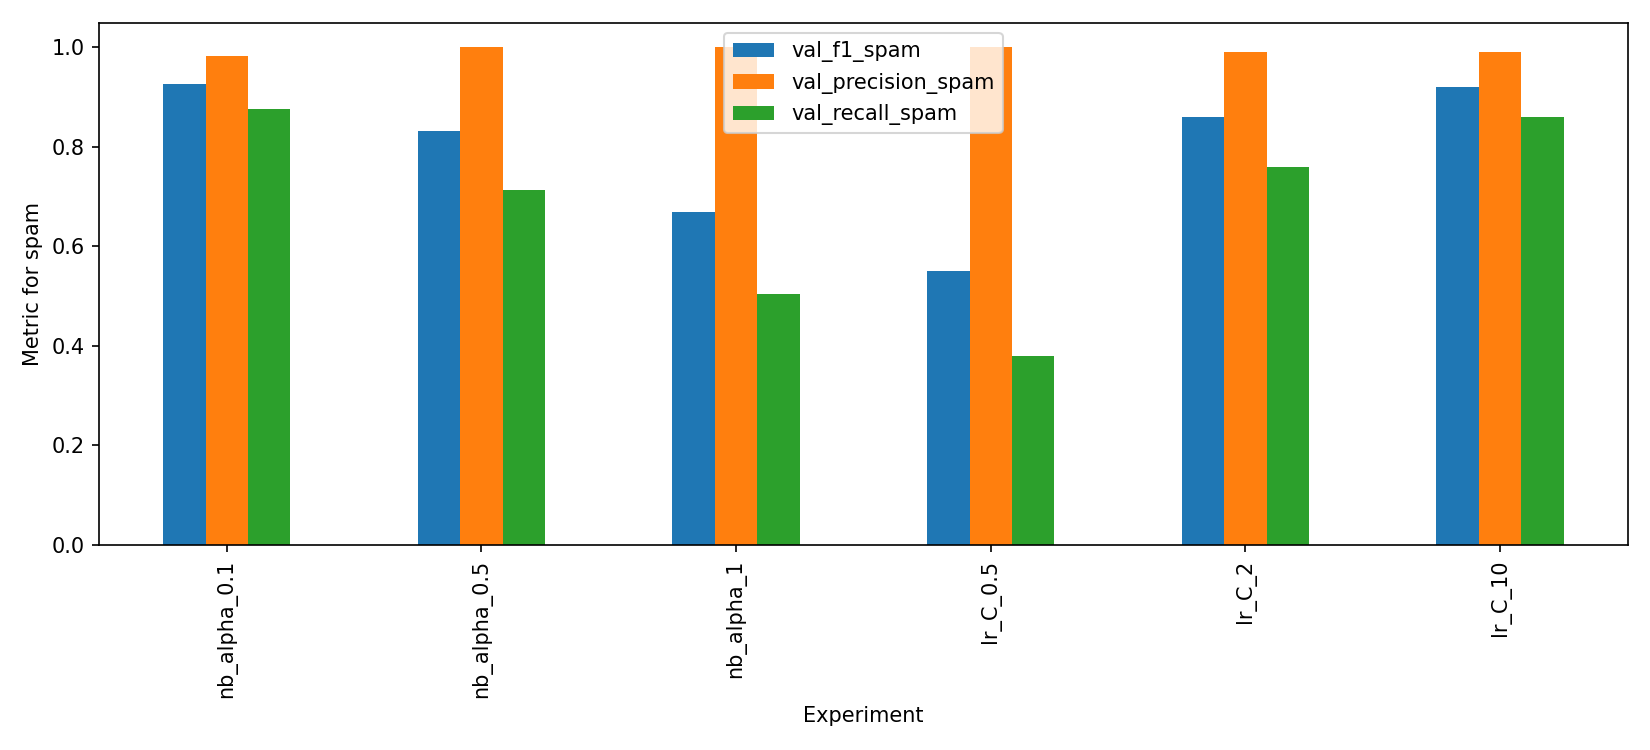

**Рисунок 2. Сравнение validation F1, precision и recall для spam.**

**Рисунок 3. Validation-метрики и размер словаря шести запусков MLflow.**

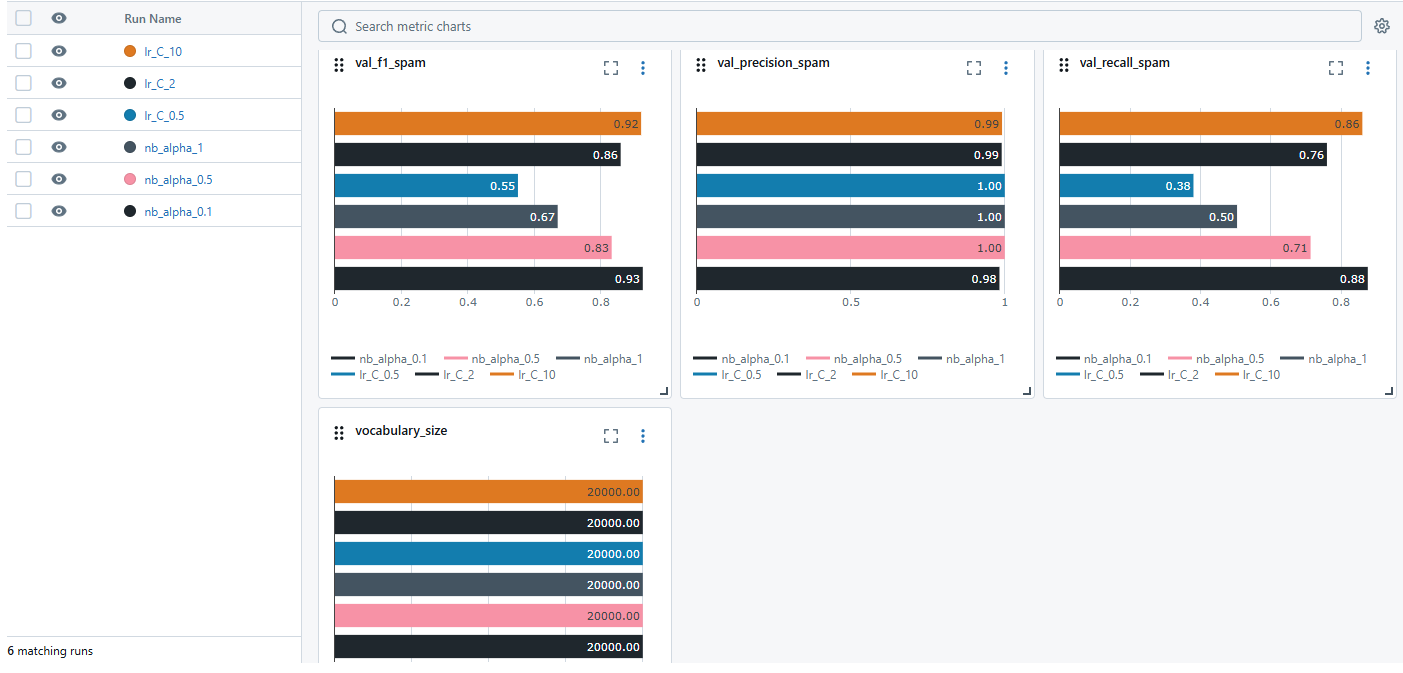

Теги выбранного запуска: {
  "mlflow.user": "tair",
  "mlflow.source.name": "/home/tair/NETI/AI/lab4/sms_mlops/train.py",
  "mlflow.source.type": "LOCAL",
  "mlflow.source.git.commit": "92bca3aed8c89aaac2313d40bffeca39f6e269f4",
  "mlflow.runName": "nb_alpha_0.1",
  "variant": "2",
  "purpose": "lab4",
  "config_id": "nb_alpha_0.1",
  "dataset_sha256": "7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d",
  "split_sha256": "c7c7f9c6bd2b5ab276809d4b7b134446449498cda7385b9e78e99e8fea279c5b",
  "selection_metric": "val_f1_spam",
  "positive_class": "spam",
  "mlflow.log-model.history": "[{\"run_id\": \"4f7499ea175841c5a006088d92de6714\", \"artifact_path\": \"model\", \"utc_time_created\": \"2026-11-10 11:57:44.942793\", \"model_uuid\": \"392872a2e54149fc9fe9f08d0c740525\", \"flavors\": {\"python_function\": {\"model_path\": \"model.pkl\", \"predict_fn\": \"predict\", \"loader_module\": \"mlflow.sklearn\", \"python_version\": \"3.12.3\", \"env\": {\"conda\": \"conda.yaml\", \

In [5]:
columns = ['algorithm', 'parameter', 'value', 'val_f1_spam', 'val_precision_spam',
           'val_recall_spam', 'val_accuracy', 'fit_seconds', 'run_id']
table(experiments[columns].sort_values(['val_f1_spam', 'val_precision_spam'], ascending=False))
display(Image(filename=str(ROOT / 'results/figures/experiments.png'), width=1100))
display(Markdown('**Рисунок 2. Сравнение validation F1, precision и recall для spam.**'))
screenshot('06_mlflow_validation_metrics.png',
           '**Рисунок 3. Validation-метрики и размер словаря шести запусков MLflow.**')
run_example = client.get_run(summary['champion']['run_id'])
print('Теги выбранного запуска:', json.dumps(run_example.data.tags, ensure_ascii=False, indent=2))
print('Артефакты:', [item.path for item in client.list_artifacts(run_example.info.run_id)])

Увеличение `alpha` усиливает сглаживание NB. В полученном сравнении модель становится
более консервативной: precision достигает 1, но recall и F1 падают.
У LogisticRegression рост `C` ослабляет регуляризацию и в исследованном диапазоне
повышает recall. Это наблюдение относится к данному разбиению, а не является
гарантией монотонного улучшения для любых данных и параметров.

## 7. Выбор модели и итоговая оценка

Выбирается лучший run по validation F1 для spam. Разница между лидерами мала;
по одному разбиению нельзя утверждать статистически доказанное превосходство.
Сетка и порог после просмотра test не менялись.
Pipeline остаётся обученным на train: дополнительного переобучения на train+validation
в этом протоколе нет. Это сохраняет полное соответствие между сравнённым run,
Registry-версией, экспортом и итоговой оценкой.

Выбрана **MultinomialNB**, `alpha=0.1`. Validation F1 = **0.926230**, precision = 0.982609, recall = 0.875969. Лучший представитель другого семейства: LogisticRegression, validation F1 = 0.921162.

,test_f1_spam,test_precision_spam,test_recall_spam,test_accuracy
0,0.925620,0.982456,0.875000,0.982558


,precision,recall,f1-score,support
ham,0.982571,0.997788,0.990121,904.000000
spam,0.982456,0.875000,0.925620,128.000000
accuracy,0.982558,0.982558,0.982558,0.982558
macro avg,0.982513,0.936394,0.957870,1032.000000
weighted avg,0.982557,0.982558,0.982121,1032.000000


**Рисунок 4. Время обучения шести моделей и test accuracy/F1 выбранной модели.**

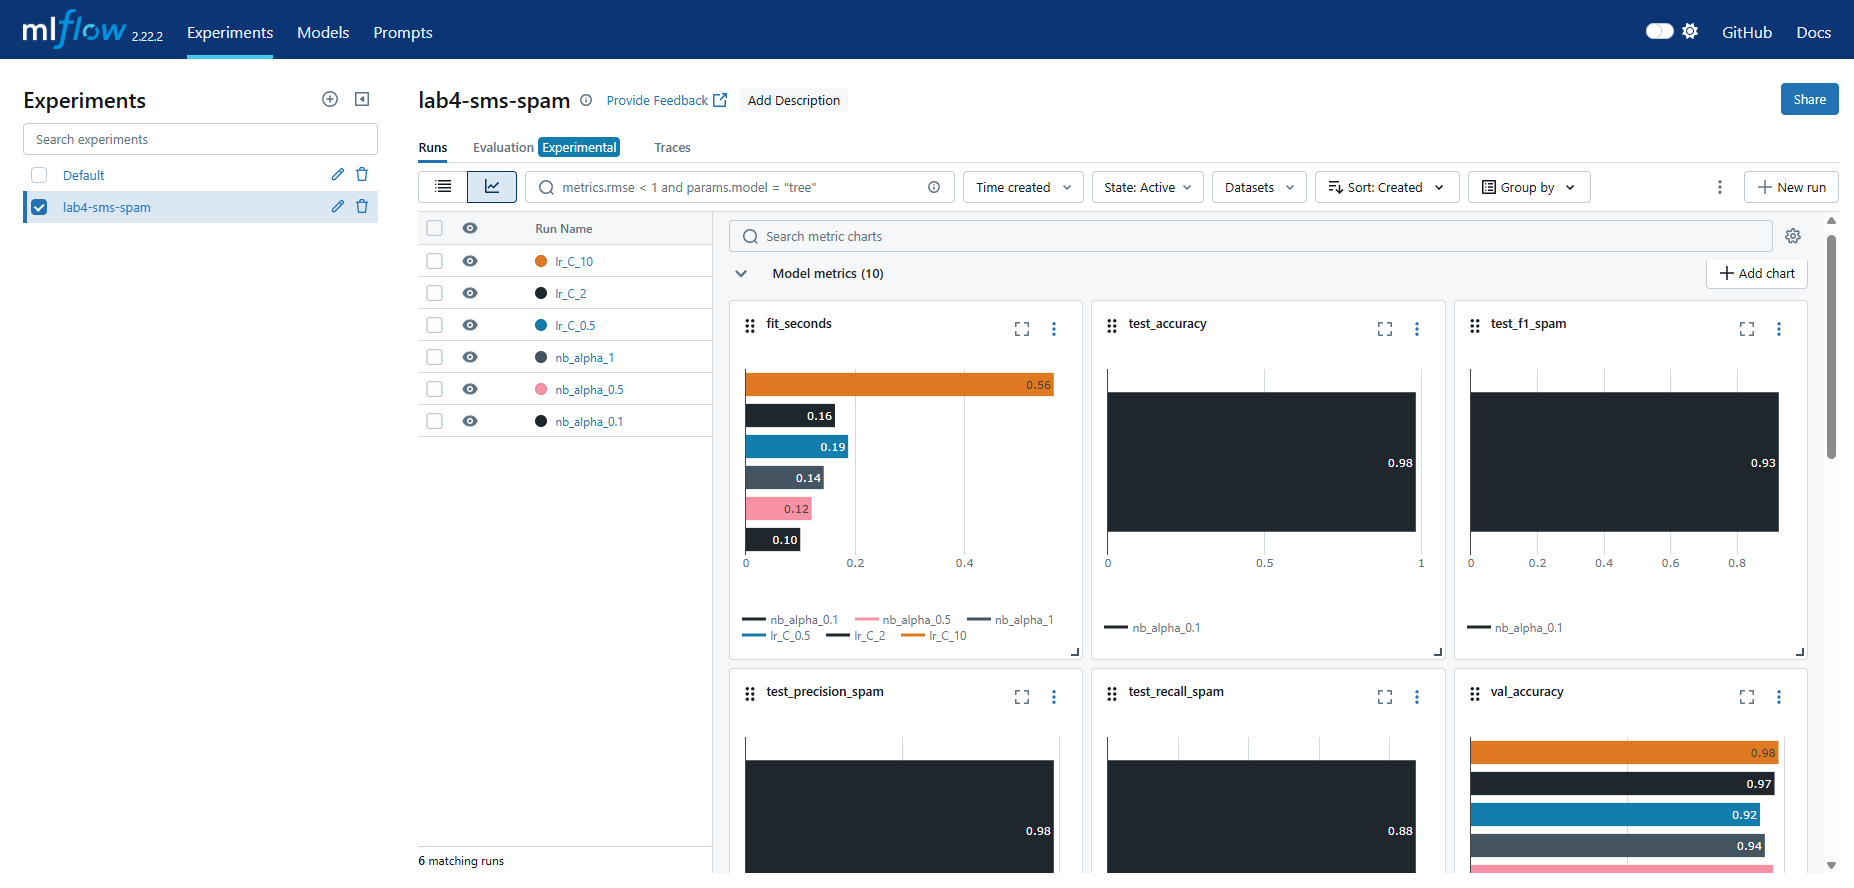

**Рисунок 5. Test precision/recall чемпиона и validation accuracy шести моделей.**

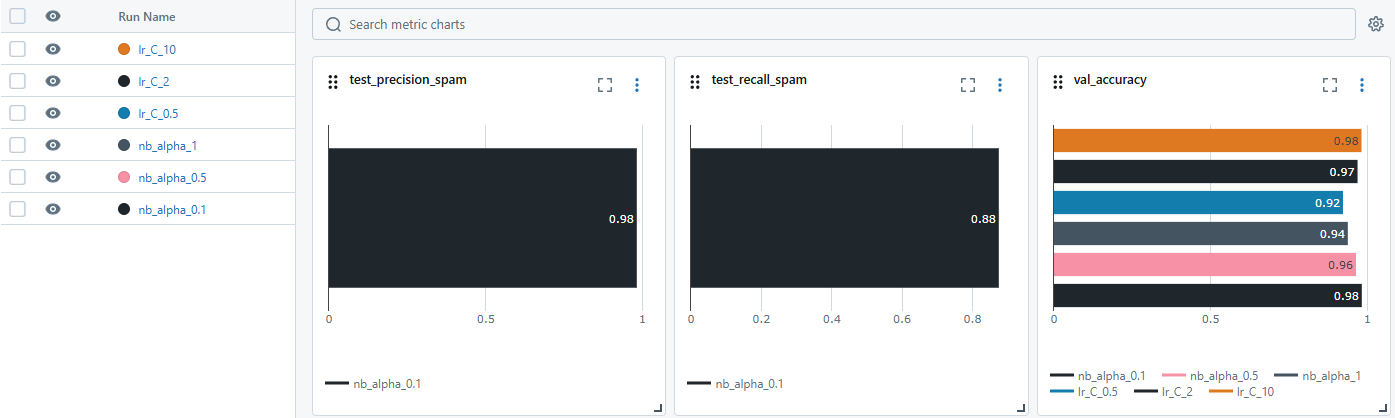

На графиках test-метрик показан один run — выбранный `nb_alpha_0.1`. Остальные модели сравнивались по validation; test не использовался для их выбора. Подписи столбцов в MLflow округлены, точные значения приведены в таблицах отчёта.

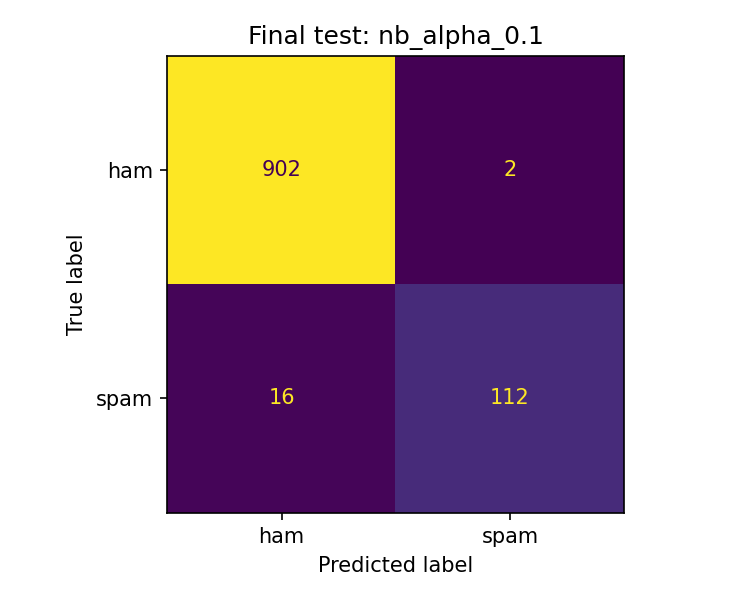

**Рисунок 6. Матрица ошибок выбранного Pipeline на test.**

На test из 1032 сообщений правильно найдены **112** spam, пропущены **16** spam; **2** обычных SMS ошибочно помечены spam, **902** ham распознаны правильно. Recall 87.500% показывает, что высокая точность ещё не означает обнаружение всего спама.

In [6]:
winner = summary['champion']
runner_up = summary['alternative']
final = read_json(ROOT / 'results/test_metrics.json')
display(Markdown(
    f"Выбрана **{winner['algorithm']}**, `{winner['parameter']}={winner['value']:g}`. "
    f"Validation F1 = **{winner['val_f1_spam']:.6f}**, "
    f"precision = {winner['val_precision_spam']:.6f}, recall = {winner['val_recall_spam']:.6f}. "
    f"Лучший представитель другого семейства: {runner_up['algorithm']}, "
    f"validation F1 = {runner_up['val_f1_spam']:.6f}."))
table(pd.DataFrame([{k: v for k, v in final.items() if k.startswith('test_')}]))
display(pd.DataFrame(final['classification_report']).T)
screenshot('07_mlflow_metrics_overview.png',
           '**Рисунок 4. Время обучения шести моделей и test accuracy/F1 выбранной модели.**')
screenshot('08_mlflow_test_metrics.png',
           '**Рисунок 5. Test precision/recall чемпиона и validation accuracy шести моделей.**')
display(Markdown('На графиках test-метрик показан один run — выбранный `nb_alpha_0.1`. '
                 'Остальные модели сравнивались по validation; test не использовался для их выбора. '
                 'Подписи столбцов в MLflow округлены, точные значения приведены в таблицах отчёта.'))
display(Image(filename=str(ROOT / 'results/figures/test_confusion_matrix.png'), width=600))
display(Markdown('**Рисунок 6. Матрица ошибок выбранного Pipeline на test.**'))
tn, fp, fn, tp = np.array(final['confusion_matrix']).ravel()
display(Markdown(
    f"На test из {final['rows']} сообщений правильно найдены **{tp}** spam, "
    f"пропущены **{fn}** spam; **{fp}** обычных SMS ошибочно помечены spam, "
    f"**{tn}** ham распознаны правильно. Recall {final['test_recall_spam']:.3%} "
    "показывает, что высокая точность ещё не означает обнаружение всего спама."))

## 8. Registry, версии и alias champion

Два уже обученных Pipeline регистрируются под одним именем `sms-spam-filter`;
повторное обучение при регистрации не выполняется.
`v1` — лучший представитель другого семейства алгоритмов, `v2` — выбранный чемпион.
Номер Registry читается из ответа MLflow, а не предполагается по тегу образа.

Alias `champion` назначается `v2`. При экспорте alias разрешается один раз в конкретный
номер версии, затем загружается `models:/sms-spam-filter/<номер>`.
Смена alias сама по себе не меняет уже собранный образ или работающий контейнер.

,релиз,Registry version,run_id,algorithm,pipeline_sha256
0,v1,1,cd9cab5f394d490a9600eea8e5c0dfd2,LogisticRegression,05026fb8bbed4155e1b3ba8d1ab998765194d9f44fde16...
1,v2,2,4f7499ea175841c5a006088d92de6714,MultinomialNB,c4c5c73d8343999dde42addb99cb0650bbf78be2566870...


champion → Registry version 2


**Рисунок 7. Две версии одной модели и alias champion.**

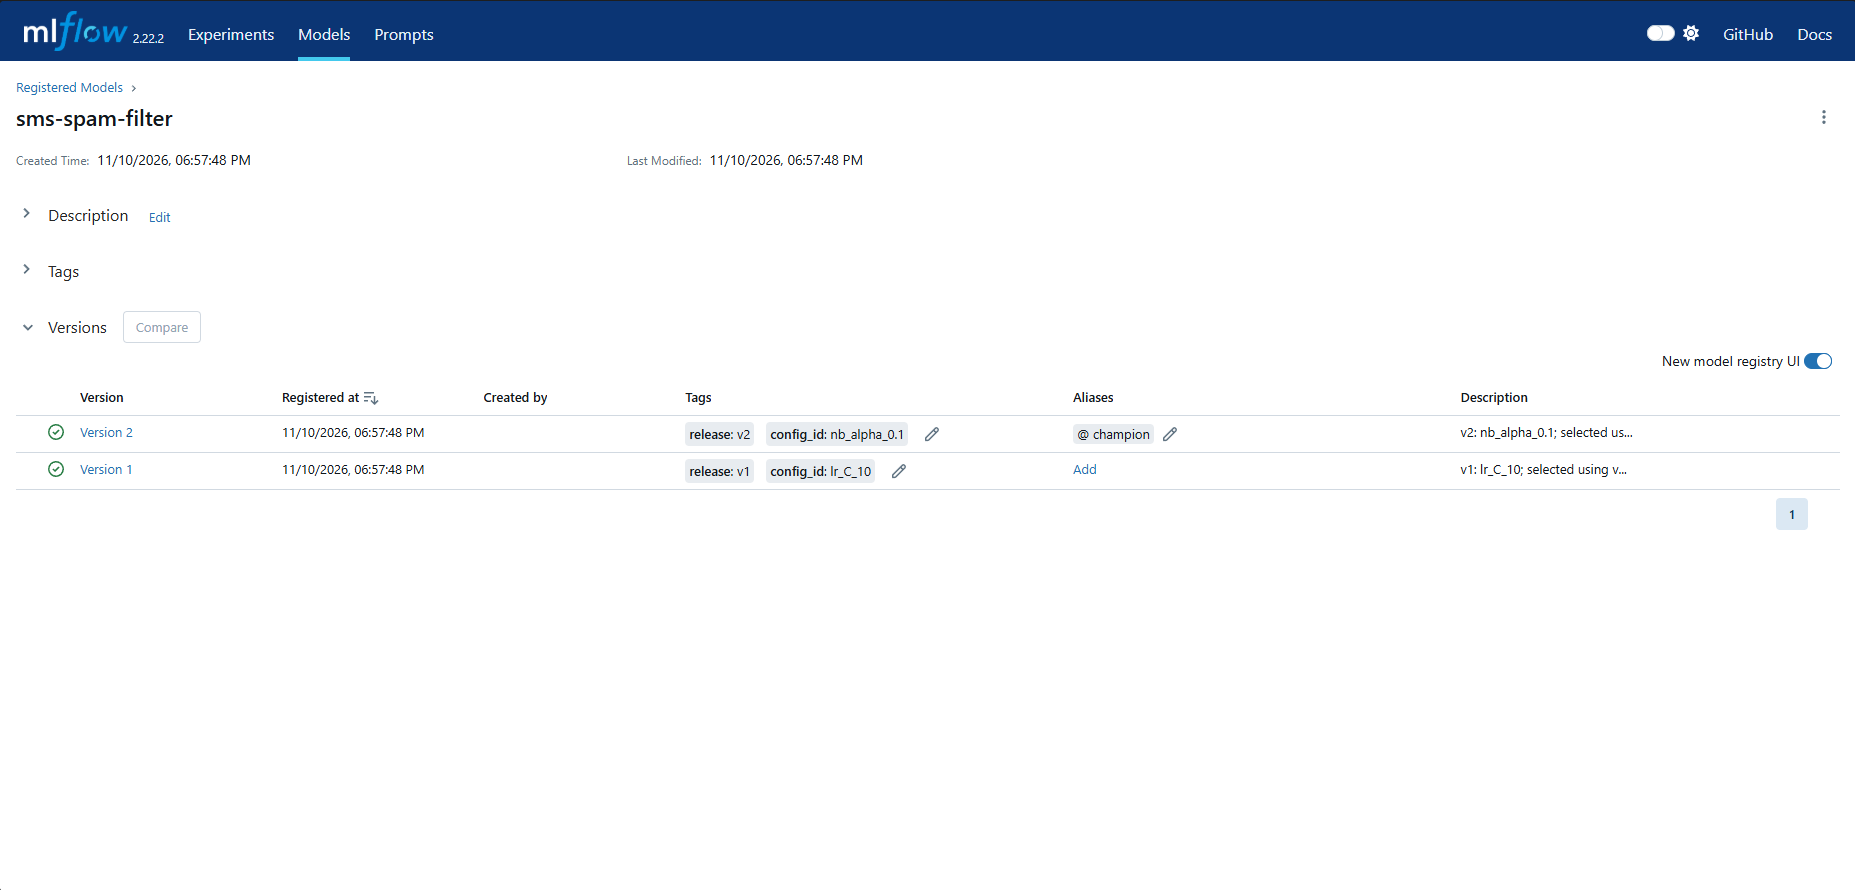

Метаданные экспорта v2:
{
  "model_name": "sms-spam-filter",
  "model_version": "2",
  "release": "v2",
  "run_id": "4f7499ea175841c5a006088d92de6714",
  "model_uri": "models:/sms-spam-filter/2",
  "pipeline_sha256": "c4c5c73d8343999dde42addb99cb0650bbf78be256687014a6f0ea223f4a3d08",
  "raw_sha256": "7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d",
  "split_sha256": "c7c7f9c6bd2b5ab276809d4b7b134446449498cda7385b9e78e99e8fea279c5b",
  "classes": {
    "0": "ham",
    "1": "spam"
  },
  "input": {
    "texts": "1..100 nonblank strings; each <=5000 characters"
  },
  "threshold": 0.5,
  "python": "3.12.3",
  "scikit_learn": "1.6.1",
  "algorithm": "MultinomialNB",
  "exported_at": "2026-11-10T11:57:49.209954+00:00"
}


In [7]:
registered = []
for release, info in summary['releases'].items():
    version = client.get_model_version(MODEL_NAME, info['model_version'])
    registered.append({'релиз': release, 'Registry version': str(version.version),
                       'run_id': version.run_id, 'algorithm': info['algorithm'],
                       'pipeline_sha256': info['pipeline_sha256']})
display(pd.DataFrame(registered))
alias = client.get_model_version_by_alias(MODEL_NAME, 'champion')
print('champion → Registry version', alias.version)
assert str(alias.version) == summary['releases']['v2']['model_version']
screenshot('02_registry.png', '**Рисунок 7. Две версии одной модели и alias champion.**')
print('Метаданные экспорта v2:')
print(json.dumps(read_json(ROOT / 'models/v2/metadata.json'), ensure_ascii=False, indent=2))

## 9. API и проверка запросов

`GET /health` — готовность загруженной модели и её версия;
`GET /metadata` — происхождение, версия, run_id и SHA-256;
`POST /predict` — пакетное предсказание;
`GET /docs` — Swagger UI.

Вход: `{"texts": ["See you soon", "Claim your free prize now!"]}`.
Допускается 1–100 строк, каждая содержит 1–5000 символов и не состоит целиком из пробелов.
Числа, `null`, пустые пакеты, лишние поля и повреждённый JSON возвращают **422**.
Ответ содержит метки `ham/spam`, вероятности spam, Registry version, release, run_id
и `latency_ms`. Эта вероятность не проходила отдельную калибровку.

Модель загружается один раз при старте. Проверяется SHA-256 и порядок классов;
повреждённый экспорт не позволяет запустить приложение.
API использует `joblib + scikit-learn`, не обращаясь к MLflow во время предсказания.
При равенстве вероятностей выбирается ham, как при `Pipeline.predict`.

Корректный запрос:
{
  "texts": [
    "And how you will do that, princess? :)",
    "cmon babe, make me horny, *turn* me on! Txt me your fantasy now babe -) Im hot, sticky and need you now. All replies cost £1.50. 2 cancel send STOP",
    "\"For the most sparkling shopping breaks from 45 per person; call 0121 2025050 or visit www.shortbreaks.org.uk\""
  ]
}
Ответ API:
{
  "predictions": [
    "ham",
    "ham",
    "ham"
  ],
  "probabilities_spam": [
    0.0010209079134395204,
    0.1632287445930936,
    0.4945835957774673
  ],
  "model_version": "2",
  "release": "v2",
  "run_id": "4f7499ea175841c5a006088d92de6714",
  "latency_ms": 1.2056240002493723
}


,case,expected_status,actual_status
0,missing_texts,422,422
1,empty_batch,422,422
2,empty_sms,422,422
3,blank_sms,422,422
4,number,422,422
5,boolean,422,422
6,null_sms,422,422
7,mixed_types,422,422
8,string_instead_of_batch,422,422
9,null_batch,422,422


Совпадение с экспортом проверено на 1037 сообщениях для каждой версии.


**Рисунок 8. Реальный POST /predict через Swagger, ответ 200.**

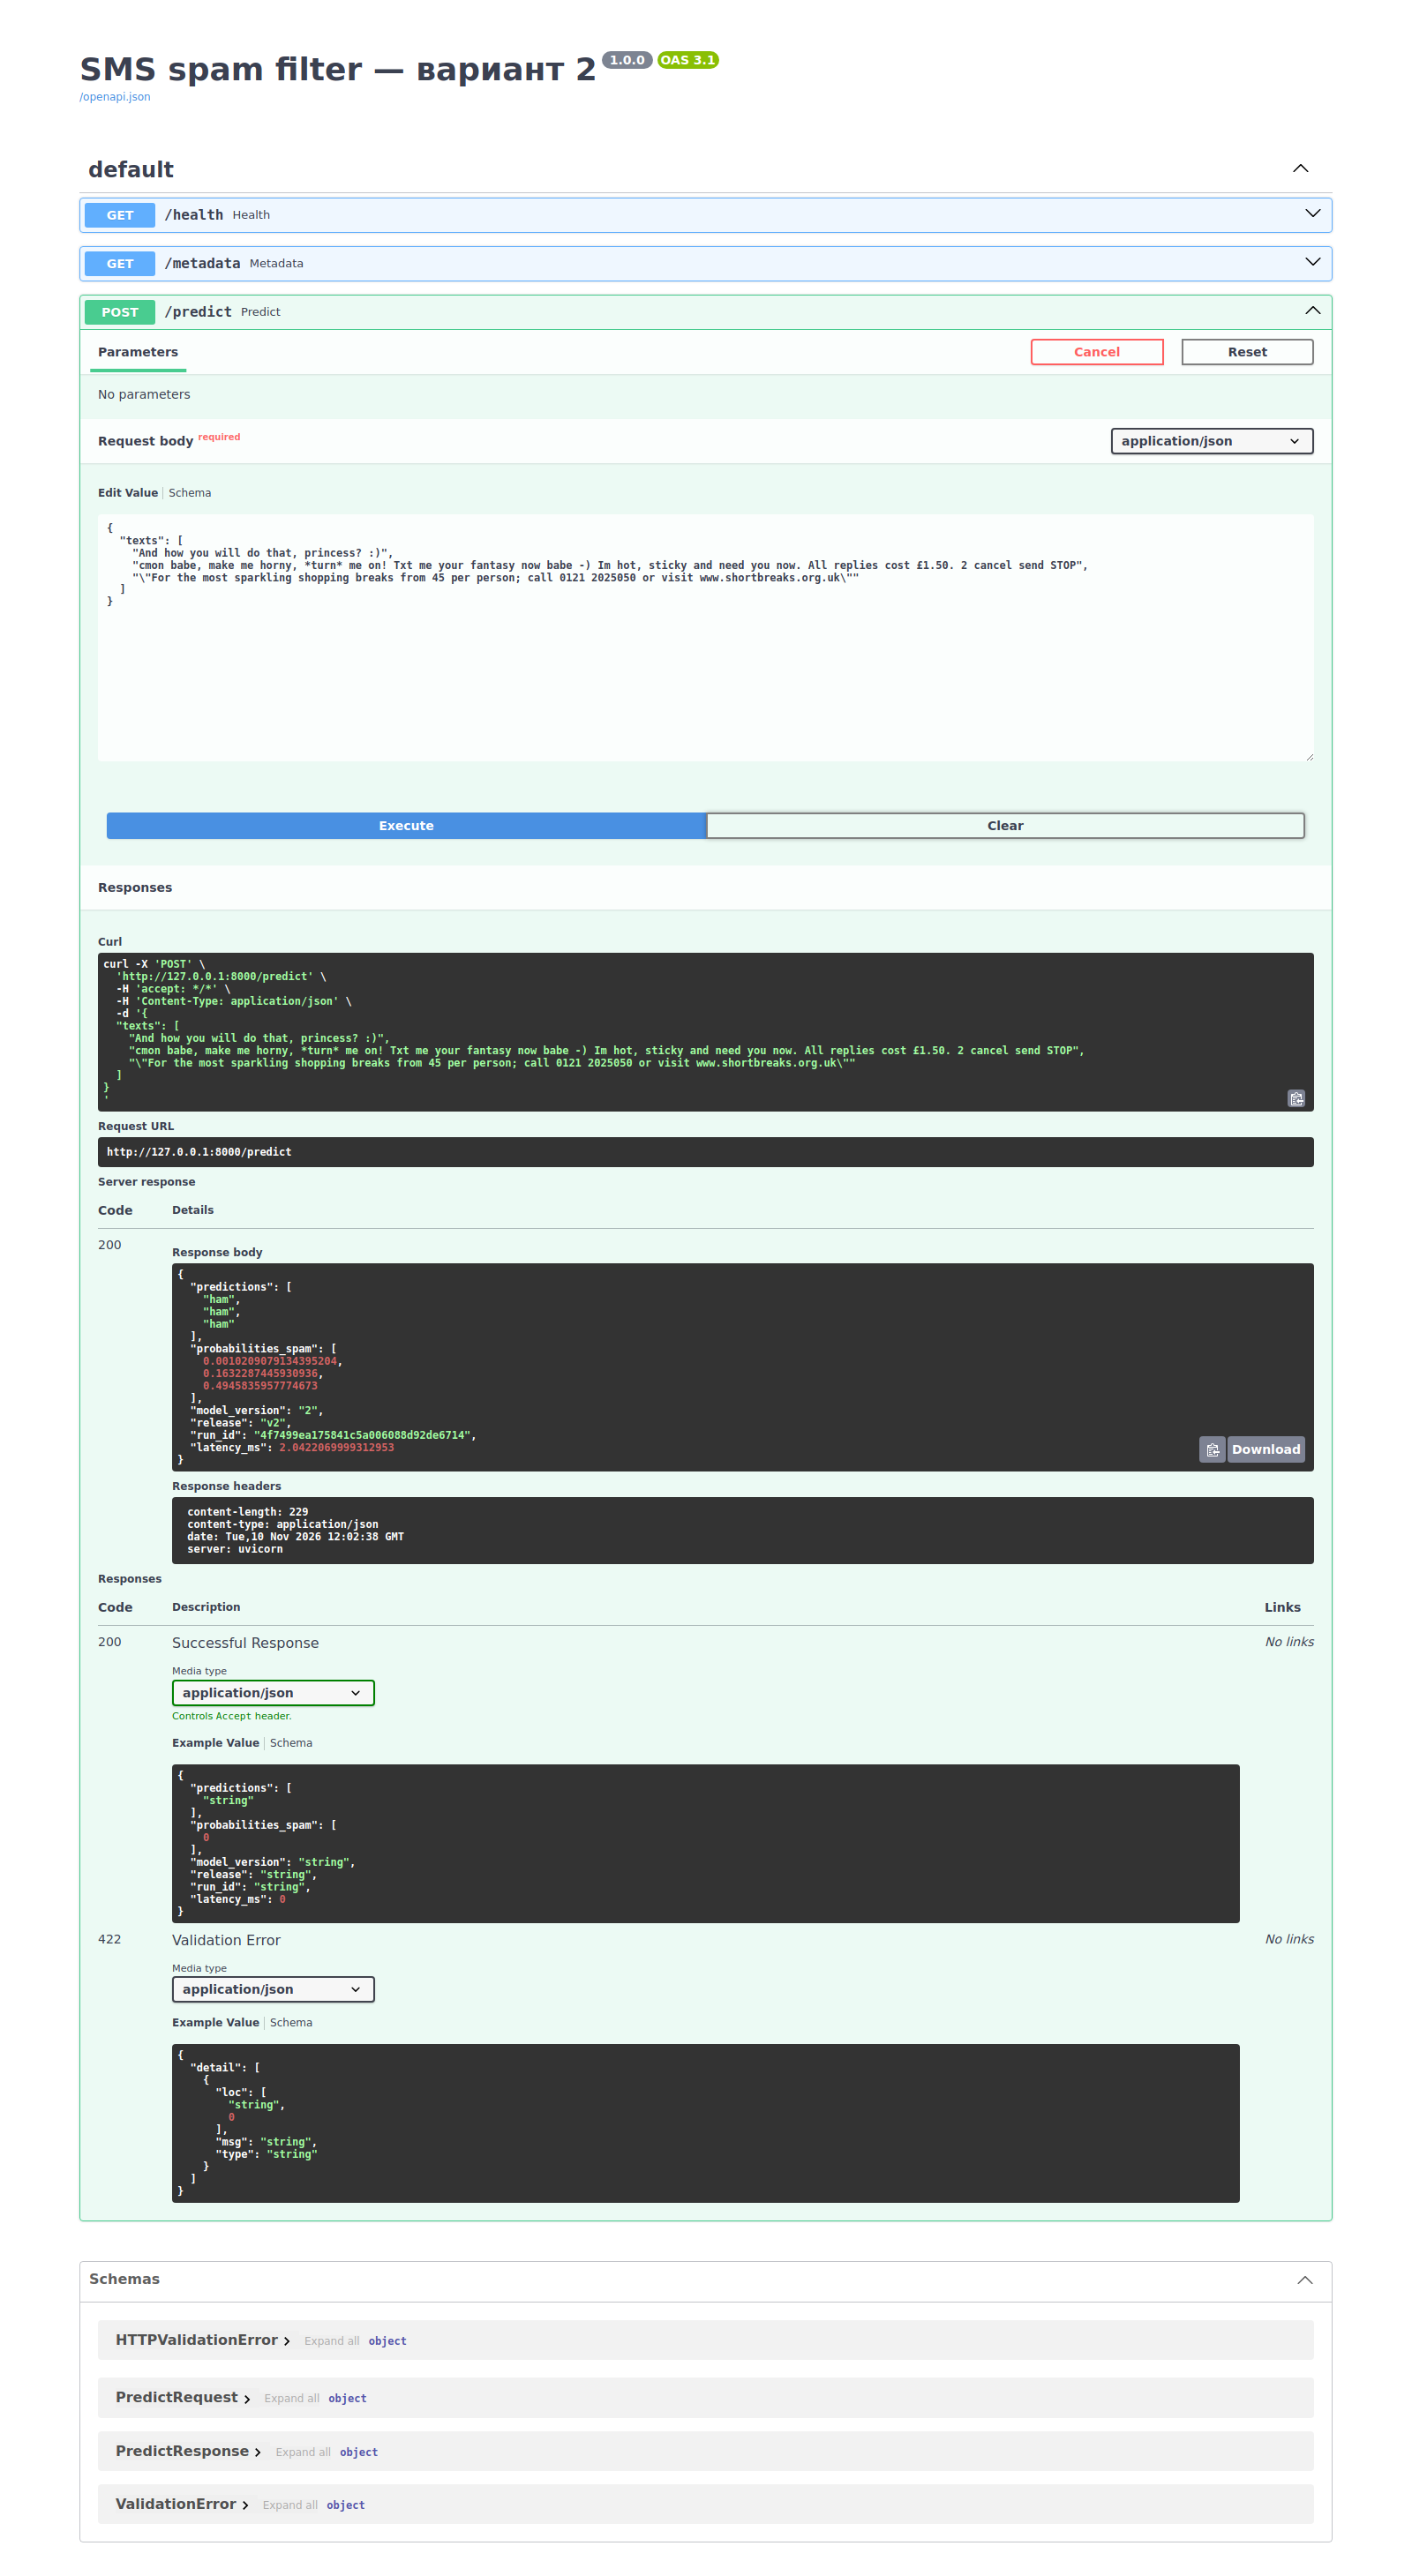

**Рисунок 9. Реальный пустой пакет и ответ 422.**

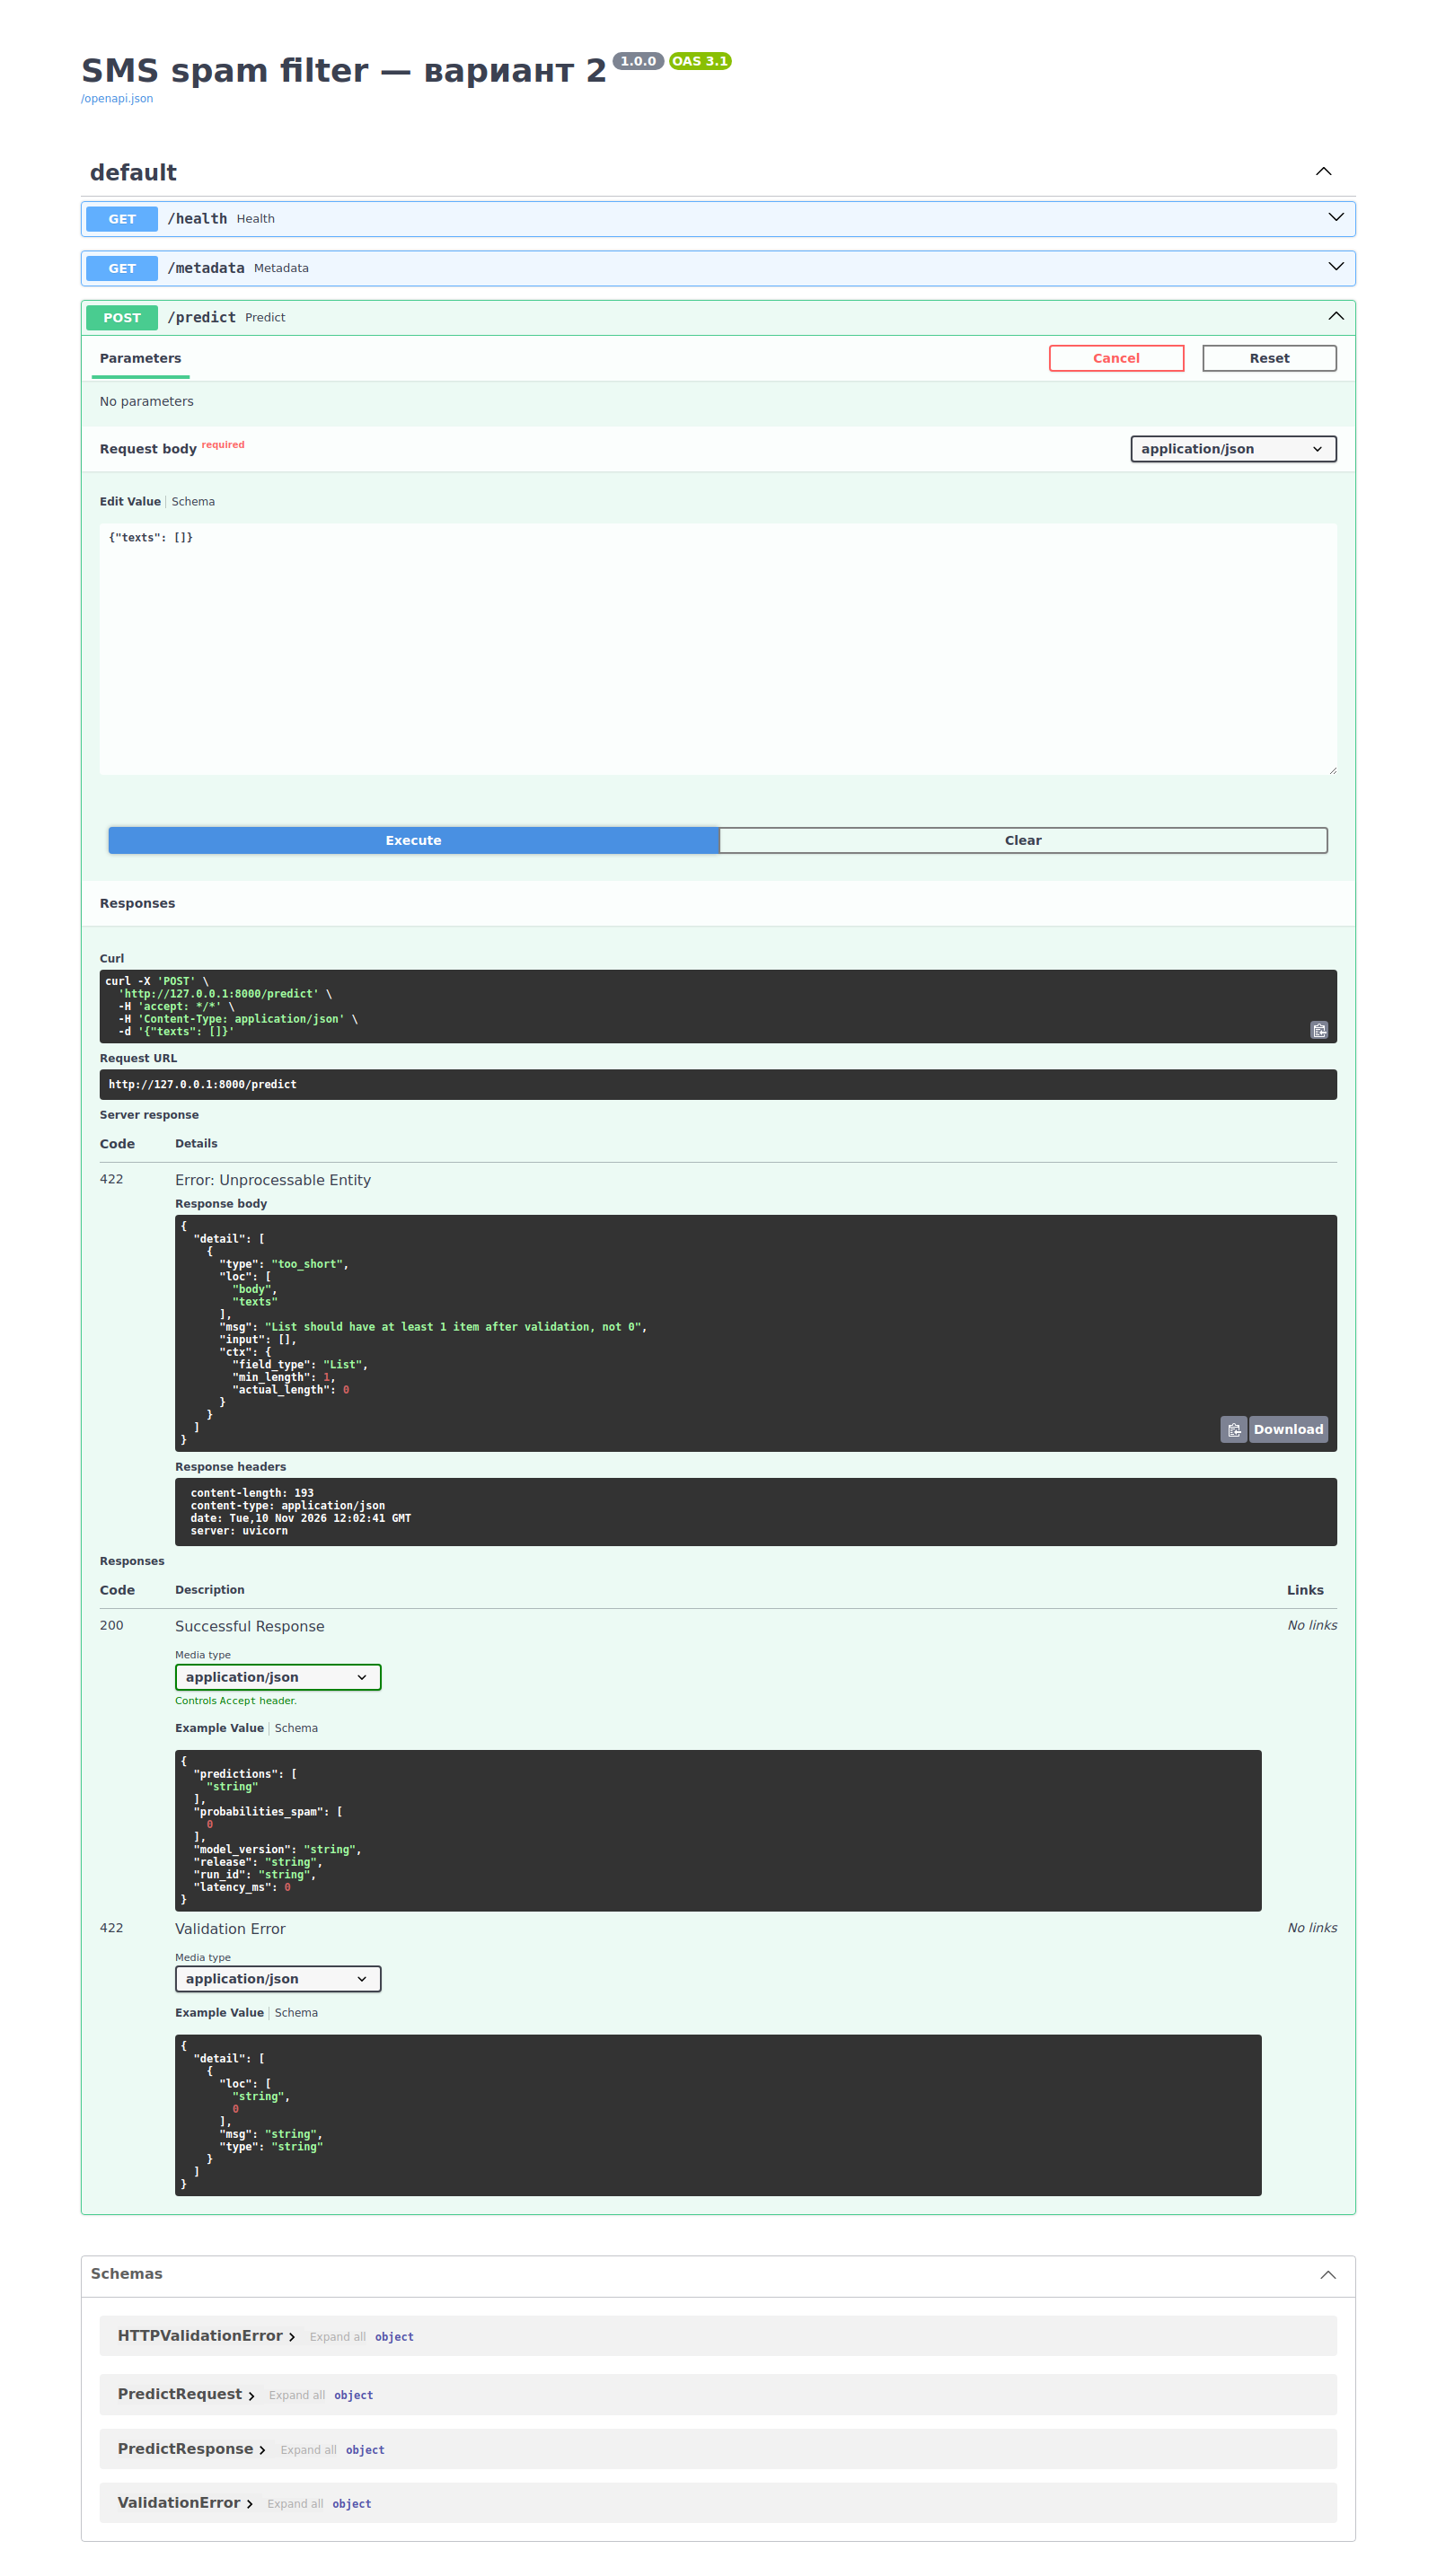

In [8]:
from sms_mlops.verify import run_local
local_checks = run_local()
local_v2 = local_checks['sequence'][1]
print('Корректный запрос:')
print(json.dumps(local_v2['example_request'], ensure_ascii=False, indent=2))
print('Ответ API:')
print(json.dumps(local_v2['example_response'], ensure_ascii=False, indent=2))
display(pd.DataFrame(local_v2['invalid_requests']))
print('Совпадение с экспортом проверено на', local_v2['parity_rows'], 'сообщениях для каждой версии.')
screenshot('03_swagger_valid.png', '**Рисунок 8. Реальный POST /predict через Swagger, ответ 200.**')
screenshot('04_swagger_invalid.png', '**Рисунок 9. Реальный пустой пакет и ответ 422.**')

Корректность запроса означает соответствие контракту API. Она не гарантирует правильную
классификацию каждого текста. Качество определяется метриками на истинных метках test.
Smoke-test сравнивает ответы API с экспортированной моделью, включая все 1 032 test-SMS
и пять дополнительных строк (Unicode, неизвестные токены, предельная длина).
Для вероятностей проверяется `allclose(rtol=1e-10, atol=1e-12)`.

```bash
curl -sS http://127.0.0.1:8000/health
curl -sS http://127.0.0.1:8000/metadata
curl -sS -X POST http://127.0.0.1:8000/predict \
  -H 'Content-Type: application/json' --data-binary @examples/valid.json
curl -i -X POST http://127.0.0.1:8000/predict \
  -H 'Content-Type: application/json' --data-binary @examples/invalid_empty.json
python -m sms_mlops.verify --url http://127.0.0.1:8000 --release v2
```

## 10. Сборка и запуск Docker, совпадение предсказаний

Dockerfile фиксирует Python 3.12.10 на Debian bookworm, устанавливает только runtime lock,
копирует API и конкретный экспорт. Контейнер работает от пользователя `appuser` (UID 10001).
Uvicorn слушает `0.0.0.0:8000` внутри контейнера; наружу порт публикуется на `127.0.0.1`.
`.dockerignore` исключает данные, SQLite, отчёт и виртуальное окружение из контекста сборки.

```bash
docker build --build-arg MODEL_RELEASE=v1 -t sms-spam:v1 .
docker build --build-arg MODEL_RELEASE=v2 -t sms-spam:v2 .
docker run --rm -d --name lab4-sms-demo -p 127.0.0.1:18000:8000 sms-spam:v1
python -m sms_mlops.verify --url http://127.0.0.1:18000 --release v1
docker stop lab4-sms-demo
```

Следующая ячейка показывает сохранённый протокол настоящего Docker-сценария.
Для повторного запуска контейнерных проверок установить `LAB4_RUN_DOCKER=1`
**перед запуском ядра**. Существующие образы проверяются без повторной сборки.
Для новой сборки с подробным build-протоколом выполнить отдельную команду
`python -m sms_mlops.docker_demo --require`.

In [9]:
if os.environ.get('LAB4_RUN_DOCKER', '0') == '1':
    completed = subprocess.run([sys.executable, '-m', 'sms_mlops.docker_demo', '--require', '--no-build'],
                               cwd=ROOT, text=True, capture_output=True, timeout=900)
    print(completed.stdout)
    if completed.returncode:
        print(completed.stderr)
        raise RuntimeError('Контейнерные проверки завершились ошибкой')
docker_checks = read_json(ROOT / 'results/docker_checks.json')
print('Статус Docker:', docker_checks['status'])
print('Дата контейнерного протокола (UTC):', docker_checks['created_at'])
if docker_checks['status'] != 'passed':
    display(Markdown('**Docker не проверен:** ' + docker_checks.get('reason', 'нет протокола')))
else:
    display(pd.DataFrame([
        {'release': release, 'image_tag': item['tag'], 'image_id': item['id'],
         'размер, MiB': item['size_bytes'] / 1024**2}
        for release, item in docker_checks['images'].items()]))
    display(pd.DataFrame([
        {'release': item['release'], 'Registry version': item['model_version'],
         'проверено строк': item['parity_rows'],
         'макс. разность вероятностей': item['max_probability_difference'], 'статус': item['status']}
        for item in docker_checks['sequence']]))

Статус Docker: passed
Дата контейнерного протокола (UTC): 2026-11-10T12:13:17.847343+00:00


,release,image_tag,image_id,"размер, MiB"
0,v1,sms-spam:v1,sha256:6d7ceff1a14600064d4fb0c803f8cb946acbb80...,128.824903
1,v2,sms-spam:v2,sha256:7b7ed92ef13698f3cf6e985cf5448257c70f54b...,128.956690


,release,Registry version,проверено строк,макс. разность вероятностей,статус
0,v1,1,1037,0.0,passed
1,v2,2,1037,0.0,passed
2,v1,1,1037,0.0,passed


Полный stdout/stderr каждой Docker-команды и время её выполнения сохранены в
`results/docker_checks.json`. Image ID и RepoDigest фиксируют содержимое конкретного
образа; тег `v1/v2` сам по себе может быть перезаписан. Показанный `Size` — значение
из `docker image inspect`, не объём переданных по сети данных.
Базовый образ дополнительно закреплён по `FROM ...@sha256:...`: digest взят из
истории фактически выполненной сборки. Логи сборки доступны также в
`results/docker_build_v1.txt` и `results/docker_build_v2.txt`.

## 11. Обновление и откат без повторного обучения

Сценарий по очереди запускает `sms-spam:v1 → sms-spam:v2 → sms-spam:v1`.
Перед каждым запуском переключается alias, затем проверяются `/metadata`, версия,
предсказания, вероятности и невалидные запросы. Экспортированные файлы уже существуют:
при откате не выполняются ни обучение, ни экспорт, ни пересборка `v1`.
Возврат исходных ответов проверяется автоматически. Возможна краткая недоступность
при остановке контейнера: бесшовное обновление в этой лабораторной не реализуется.

```bash
docker run --rm -d --name lab4-sms-demo -p 127.0.0.1:18000:8000 sms-spam:v2
python -m sms_mlops.verify --url http://127.0.0.1:18000 --release v2
docker stop lab4-sms-demo
docker run --rm -d --name lab4-sms-demo -p 127.0.0.1:18000:8000 sms-spam:v1
python -m sms_mlops.verify --url http://127.0.0.1:18000 --release v1
docker stop lab4-sms-demo
```

Число run и SHA-256 экспортов до/после сверяются. После демонстрации alias возвращается
выбранному по validation чемпиону `v2`, и эта версия запускается через Compose.

In [10]:
if docker_checks['status'] == 'passed':
    display(pd.DataFrame([
        {'шаг': i + 1, 'образ': item['image_tag'], 'Registry version': item['model_version'],
         'champion во время шага': item['champion_alias'],
         'пример предсказаний': ', '.join(item['example_response']['predictions']), 'статус': item['status']}
        for i, item in enumerate(docker_checks['sequence'])]))
    proof = docker_checks['no_retraining']
    print('Число run до/после:', proof['runs_before'], '/', proof['runs_after'])
    print('Хеши моделей совпадают:', proof['hashes_before'] == proof['hashes_after'])
    assert proof['runs_before'] == proof['runs_after']
    assert proof['hashes_before'] == proof['hashes_after']
    display(pd.DataFrame([
        {'шаг': i + 1, 'версия': item['release'], **item['latency']}
        for i, item in enumerate(docker_checks['sequence'])]))
    display(Markdown('Медиана `handler_median_ms` измеряет вычисление в обработчике; '
                     '`roundtrip_median_ms` включает HTTP и сериализацию. '
                     'Десять последовательных запросов — smoke-измерение, '
                     'они не заменяют нагрузочный тест и не дают гарантии SLA.'))

,шаг,образ,Registry version,champion во время шага,пример предсказаний,статус
0,1,sms-spam:v1,1,1,"ham, ham, spam",passed
1,2,sms-spam:v2,2,2,"ham, ham, ham",passed
2,3,sms-spam:v1,1,1,"ham, ham, spam",passed


Число run до/после: 6 / 6
Хеши моделей совпадают: True


,шаг,версия,requests,batch_size,roundtrip_median_ms,roundtrip_p95_ms,handler_median_ms
0,1,v1,10,3,2.315728,2.964164,0.718120
1,2,v2,10,3,2.474710,3.162584,0.870741
2,3,v1,10,3,2.724100,2.926428,0.819027


Медиана `handler_median_ms` измеряет вычисление в обработчике; `roundtrip_median_ms` включает HTTP и сериализацию. Десять последовательных запросов — smoke-измерение, они не заменяют нагрузочный тест и не дают гарантии SLA.

## 12. Docker Compose и healthcheck

```bash
MODEL_RELEASE=v2 docker compose up -d --no-build --wait --wait-timeout 90
docker compose ps
docker inspect --format '{{.State.Health.Status}}' "$(docker compose ps -q api)"
curl -f http://127.0.0.1:8000/health
```

Compose использует уже собранный образ. Проверка каждые 5 секунд запрашивает `/health`
изнутри контейнера, timeout 3 секунды, начальный период 10 секунд, до 5 ошибок.
`--wait` ожидает готовности по healthcheck. `restart: unless-stopped` перезапускает
завершившийся контейнер, но сам по себе не перезапускает контейнер только из-за unhealthy.
Остановка после работы: `docker compose down`.

docker compose ps:
{"Command":"\"python -m uvicorn s…\"","CreatedAt":"2026-11-10 19:13:30 +0700 +07","ExitCode":0,"Health":"healthy","ID":"9c091f59d5af","Image":"sms-spam:v2","Labels":"com.docker.compose.project.working_dir=/home/tair/NETI/AI/lab4,com.docker.compose.version=5.1.4,desktop.docker.io/ports/8000/tcp=127.0.0.1:8000,desktop.docker.io/wsl-distro=Ubuntu-24.04,com.docker.compose.config-hash=e162be60d781b85eb3463eaae9d3129a2d84c49c48f0b414773a519c1d94286e,com.docker.compose.container-number=1,com.docker.compose.oneoff=False,com.docker.compose.replace=api-1,com.docker.compose.service=api,desktop.docker.io/ports.scheme=v2,com.docker.compose.depends_on=,com.docker.compose.image=sha256:7b7ed92ef13698f3cf6e985cf5448257c70f54b71a61b25e1eeb897bb016d26d,com.docker.compose.project=lab4-sms-spam,com.docker.compose.project.config_files=/home/tair/NETI/AI/lab4/compose.yaml","LocalVolumes":"0","Mounts":"","Name":"lab4-sms-spam-api-1","Names":"lab4-sms-spam-api-1","Networks":"lab4-sms-spam_de

**Рисунок 10. Настоящий /health сервиса в Compose.**

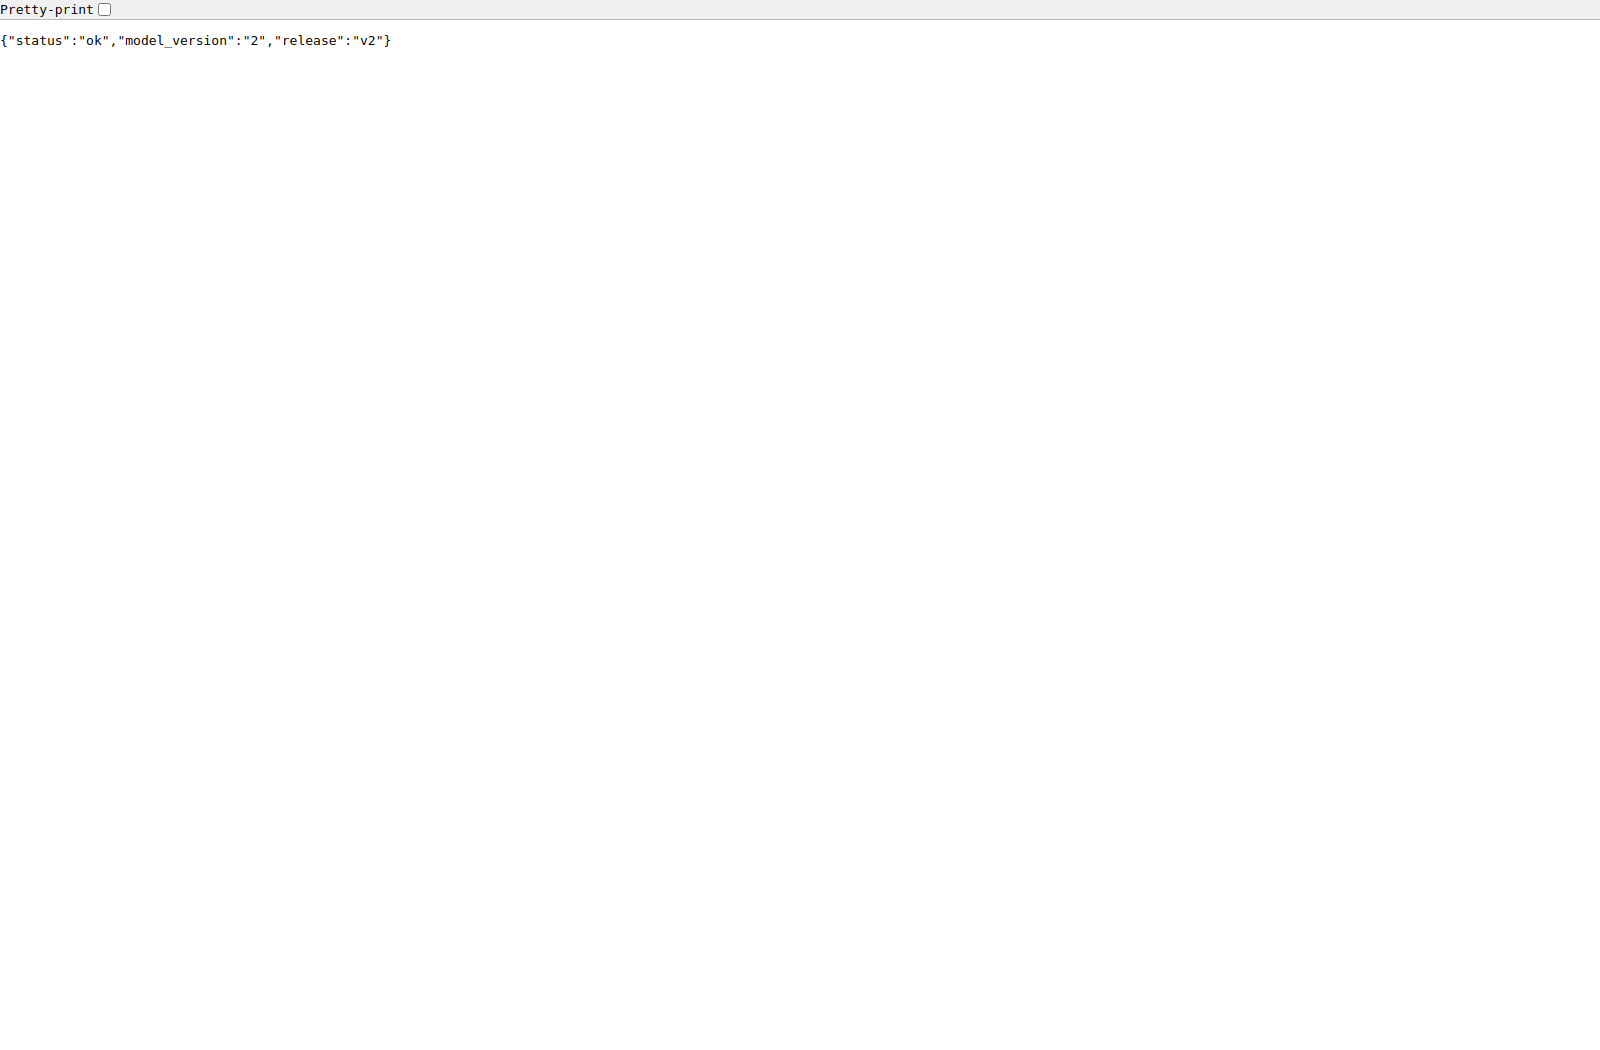

In [11]:
if docker_checks['status'] == 'passed':
    print('docker compose ps:')
    print(docker_checks['compose_ps'])
    print('Healthcheck:', docker_checks['compose_health'])
    assert docker_checks['compose_health'] == 'healthy'
    print('API Compose:', docker_checks['compose_checks']['status'])
    print('Registry version:', docker_checks['compose_checks']['model_version'])
    print('Docker и Compose:')
    print(docker_checks['docker_version'])
    print(docker_checks['compose_version'])
    screenshot('05_health.png', '**Рисунок 10. Настоящий /health сервиса в Compose.**')

## 13. Выводы

Построен воспроизводимый проект варианта 2: исходные байты UCI, журнал очистки, seed,
индексы разбиения, зависимости, MLflow runs, артефакты и два экспортированных Pipeline
сохранены в проекте. Отделение validation от test предотвращает выбор модели по
итоговой оценке, а Pipeline предотвращает обучение TF-IDF на отложенных данных.

Уменьшение alpha улучшило recall NB на данном разбиении; рост C повысил recall
LogisticRegression. Выбор сделан по F1, с отдельным анализом precision/recall.
Высокая precision сочетается с пропусками спама: модель не является безошибочным фильтром.
Исторический корпус и один случайный split ограничивают переносимость оценки.

Model Registry отделяет запуск обучения от версии модели, alias задаёт выбор для следующего
экспорта, а Docker-образ хранит конкретный снимок. Проверка полного пакета test-SMS
подтверждает соответствие API экспорту; проверка некорректного ввода подтверждает контракт.
Статусы контейнерной части и итоговые метрики ниже читаются из реальных протоколов.

In [12]:
display(Markdown(
    f"**Итог:** {winner['algorithm']} ({winner['parameter']}={winner['value']:g}); "
    f"test F1 = **{final['test_f1_spam']:.4f}**, precision = **{final['test_precision_spam']:.4f}**, "
    f"recall = **{final['test_recall_spam']:.4f}**. "
    f"Локальные проверки: **{local_checks['status']}**; "
    f"Docker: **{docker_checks['status']}**; Compose healthcheck: "
    f"**{docker_checks.get('compose_health', 'не проверен')}**."))

**Итог:** MultinomialNB (alpha=0.1); test F1 = **0.9256**, precision = **0.9825**, recall = **0.8750**. Локальные проверки: **passed**; Docker: **passed**; Compose healthcheck: **healthy**.

## 14. Список использованных источников

1. Методические материалы «Лабораторная работа 4. MLOps», PDF, предоставленный к заданию,
   особенно разделы 7–17 и индивидуальный вариант 2. Пример Wine адаптирован под текст SMS.
2. Almeida, T., Hidalgo, J. SMS Spam Collection. UCI Machine Learning Repository, 2011.
   [Страница и лицензия набора](https://archive.ics.uci.edu/dataset/228/sms+spam+collection),
   [DOI](https://doi.org/10.24432/C5CC84).
3. [MLflow Model Registry](https://mlflow.org/docs/latest/model-registry/) и
   [sklearn API](https://mlflow.org/docs/latest/api_reference/python_api/mlflow.sklearn.html).
4. [scikit-learn 1.6: Pipeline](https://scikit-learn.org/1.6/modules/compose.html),
   [text feature extraction](https://scikit-learn.org/1.6/modules/feature_extraction.html#text-feature-extraction),
   [model evaluation](https://scikit-learn.org/1.6/modules/model_evaluation.html).
5. [Dockerfile reference](https://docs.docker.com/reference/dockerfile/),
   [Compose services and healthcheck](https://docs.docker.com/reference/compose-file/services/),
   [compose up](https://docs.docker.com/reference/cli/docker/compose/up/),
   [Docker Desktop WSL integration](https://docs.docker.com/desktop/features/wsl/).
6. [FastAPI request body](https://fastapi.tiangolo.com/tutorial/body/),
   [Pydantic validators](https://docs.pydantic.dev/latest/concepts/validators/).

Документация latest может описывать другие версии: воспроизводимое окружение этой
работы задаётся локальными lock-файлами, фактические результаты — сохранёнными протоколами.

## 15. Приложение: исходные файлы и протокол выполнения

Ниже приводятся полные исходные файлы проекта, зависимости, Dockerfile, Compose и
JSON-примеры. SQLite, исходные данные, бинарные Pipeline и изображения приложены
отдельными файлами в `lab4`.
Скриншоты Registry и графиков метрик отражают состояние локального MLflow; остальные
снимки получены Playwright с реальных локальных страниц. Источники и SHA-256
изображений записаны в `screenshots/capture_metadata.json`. Оригинальные PNG сохранены
без изменений в каталоге `screenshots`.
При повторном эксперименте текст численных выводов обновляется из сохранённых результатов.

In [13]:
source_paths = [Path('README.md'), Path('requirements.in'), Path('requirements.txt'),
                Path('requirements-runtime.in'), Path('requirements-runtime.txt'),
                Path('Dockerfile'), Path('compose.yaml'), Path('.dockerignore')]
source_paths += sorted(Path('sms_mlops').glob('*.py'))
source_paths += sorted(Path('scripts').glob('*.py'))
source_paths += sorted(Path('tests').glob('*.py'))
source_paths += sorted(Path('examples').glob('*.json'))
for path in source_paths:
    # The report generator itself is linked to avoid recursively embedding the whole report.
    if path.name == 'build_report.py':
        display(Markdown(f'Генератор исходного ноутбука: [{path.as_posix()}]({path.as_posix()}).'))
        continue
    language = 'python' if path.suffix == '.py' else 'json' if path.suffix == '.json' else 'text'
    display(Markdown(f'### {path.as_posix()}\n\n```{language}\n' + path.read_text() + '\n```'))

### README.md

```text
# Лабораторная работа 4 — вариант 2: фильтрация SMS-спама

Основной результат — **[lab4_mlops.ipynb](lab4_mlops.ipynb)**, выполненный отчёт по всем 15 пунктам.
Отдельный отчёт с оформлением по образцу ЛР2: **[Word](Отчёт_ЛР4_MLOps.docx)**,
**[PDF](Отчёт_ЛР4_MLOps.pdf)**. В титульном листе указан Бикмухаметов Таир Олегович.
Для чтения отчёта в VS Code повторно запускать ячейки не требуется. Дополнительно сохранён
`lab4_mlops.html`, который можно открыть в обычном браузере.
Титульный лист ноутбука можно дополнить персональными данными; в Word они уже заполнены.

Word-отчёт формируется из сохранённых результатов без повторного обучения:

```bash
source .venv/bin/activate
python -m pip install -r requirements-report.txt
python scripts/build_word_report.py
```

Параметры оформления берутся из файла-образца, путь можно указать через `--template`.
PDF экспортирован установленным Microsoft Word с обновлением номеров страниц.

Проект содержит реальные данные UCI, шесть завершённых MLflow runs, две Registry-версии,
экспорты, API, Dockerfile, Compose, тесты и протокол реального обновления/отката.
На зафиксированном test у MultinomialNB(alpha=0.1): F1 spam 0.925620,
precision 0.982456, recall 0.875000. Эти числа относятся к сохранённому разбиению.

## Быстрый запуск через bash

Из корня репозитория:

```bash
./lab4/run.sh
```

Скрипт сам переходит в `lab4`, при необходимости создаёт `.venv` и устанавливает
зафиксированные зависимости. Он проверяет сохранённые модели, собирает и запускает
API с релизом **v2** через Compose, ожидает healthcheck и поднимает MLflow в фоне.
Открыть: http://127.0.0.1:8000/docs и http://127.0.0.1:5000.

```bash
./lab4/run.sh status             # состояние Compose и MLflow
./lab4/run.sh check              # проверить работающий HTTP API v2
./lab4/run.sh test               # локальные проверки API и pytest
./lab4/run.sh logs               # логи контейнера; Ctrl+C завершает просмотр
./lab4/run.sh logs mlflow        # логи фонового MLflow
./lab4/run.sh down               # остановить API и управляемый скриптом MLflow
./lab4/run.sh up v1              # запустить предыдущий релиз
./lab4/run.sh check v1           # проверить API предыдущего релиза
./lab4/run.sh up v2 --no-build   # использовать уже собранный образ
./lab4/run.sh demo               # сборка, обновление, откат и Compose
./lab4/run.sh demo --no-build    # повторить демонстрацию на готовых образах
./lab4/run.sh train --force      # новый цикл обучения, 6 runs + 2 версии
./lab4/run.sh report             # обновить выполненный IPYNB и HTML
./lab4/run.sh help               # все команды
```

После `up v1` стандартный `./lab4/run.sh` возвращает API на v2. Сам `up` не меняет
alias champion: он запускает выбранный сохранённый экспорт. Для демонстрации изменения
alias и отката предназначен `demo`.

Внутри `lab4` можно писать `./run.sh`. Ручная активация окружения не нужна.
Команда `setup` готовит только Python-окружение, `mlflow` запускает только интерфейс MLflow.
Зависимости проверяются локально перед запуском; при совпадении с lock-файлом
повторной установки пакетов не происходит.

Если стандартные порты заняты, используйте одни и те же значения для запуска,
проверки и остановки, например:

```bash
API_PORT=8001 MLFLOW_PORT=5001 ./lab4/run.sh up
API_PORT=8001 MLFLOW_PORT=5001 ./lab4/run.sh check
API_PORT=8001 MLFLOW_PORT=5001 ./lab4/run.sh down
```

Сценарий `demo` использует фиксированные порты 8000/18000 и стандартный Compose-проект.
MLflow, запущенный скриптом, хранит PID и лог в `.runtime/runner/`. Если на выбранном
порту уже работает MLflow **этого проекта**, он используется повторно. Сервер,
запущенный вручную в другом терминале, останавливается там через Ctrl+C.

`.gitignore` исключает окружения, кеши, локальные PID/логи, временные SQLite-файлы,
блокировки Word/LibreOffice и случайные каталоги `mlruns`/`mlartifacts`.
Данные, разбиение, настоящая база `mlflow-data`, экспорты, результаты и готовые отчёты
доступны для добавления в Git как материалы лабораторной.

## Подготовка в WSL Ubuntu 24.04

Docker Desktop должен работать с Linux engine. Включите
Settings → Resources → WSL Integration → Ubuntu → Apply.
Выполняйте команды в Ubuntu, из каталога проекта:

```bash
cd /home/tair/NETI/AI/lab4
python3 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements.txt
python -m pip check
docker version
docker compose version
```

Python — 3.12. Проверенный полный lock — `requirements.txt`, прямые зависимости —
`requirements.in`, минимальный runtime lock — `requirements-runtime.txt`.
Системный Python и окружения других лабораторных не изменяются.
Исходный файл уже сохранён, повторная загрузка UCI не требуется.

## Запуск полного цикла

```bash
source .venv/bin/activate
python -m sms_mlops.train
python -m sms_mlops.verify
python -m pytest -q
python -m sms_mlops.docker_demo --require
```

`train` при наличии результатов использует сохранённые runs и модели.
Для **нового обучения**: `python -m sms_mlops.train --force`.
Это добавит шесть runs и две новые Registry-версии, обновит локальные релизы `v1/v2`
и потребует заново собрать образы/выполнить отчёт. Номер Registry не равен тегу образа.

`docker_demo` собирает `sms-spam:v1` и `sms-spam:v2`, запускает их на порту 18000
в порядке v1 → v2 → v1, сверяет предсказания с экспортом, меняет alias и проверяет
неизменность числа runs и SHA-256 моделей. Затем возвращает champion версии v2
и оставляет её работающей в Compose на **127.0.0.1:8000**.
Существующий контейнер `lab4-sms-demo` автоматически не удаляется: сценарий откажется
использовать занятое имя. Детальные команды и stdout/stderr — `results/docker_checks.json`.

## Просмотр MLflow

В отдельном терминале из `lab4`:

```bash
source .venv/bin/activate
python -m sms_mlops.relocate
mlflow server --backend-store-uri sqlite:///mlflow-data/mlflow.db \
  --default-artifact-root ./mlflow-data/artifacts --no-serve-artifacts \
  --host 127.0.0.1 --port 5000 --workers 1
```

Откройте http://127.0.0.1:5000. Эксперимент `lab4-sms-spam`, модель `sms-spam-filter`,
alias `champion`. SQLite используется непосредственно при обучении; сервер нужен
для интерфейса. Запускайте его из `lab4`, чтобы пути совпадали.

При переносе всей папки на другой компьютер выполните `python -m sms_mlops.relocate`
перед запуском UI: это обновит абсолютные пути к локальным артефактам в SQLite,
сохранив резервную копию. `train` также делает это автоматически. Переносите **всю**
папку `mlflow-data`, включая артефакты. Остановите UI перед переносом/резервным копированием.

## API и Compose

```bash
MODEL_RELEASE=v2 docker compose up -d --no-build --wait --wait-timeout 90
docker compose ps
curl -f http://127.0.0.1:8000/health
curl -sS -X POST http://127.0.0.1:8000/predict \
  -H 'Content-Type: application/json' --data-binary @examples/valid.json
curl -i -X POST http://127.0.0.1:8000/predict \
  -H 'Content-Type: application/json' --data-binary @examples/invalid_empty.json
python -m sms_mlops.verify --url http://127.0.0.1:8000 --release v2
```

Если образы ещё не собраны, замените `--no-build` на `--build`.
Swagger — http://127.0.0.1:8000/docs, метаданные — `/metadata`.
Вход: `{"texts": ["Hi, see you soon!", "Claim your free prize now!"]}`.
API возвращает `predictions`, `probabilities_spam`, `model_version`, `release`, `run_id`,
`latency_ms`. Принимается 1–100 непустых строк длиной до 5000 символов;
неверные типы и лишние поля возвращают 422. Модель загружается один раз при старте.
Неизвестные слова/Unicode допустимы, но качество на русском языке не оценивалось.

Ручная сборка и запуск конкретного снимка:

```bash
docker build --build-arg MODEL_RELEASE=v1 -t sms-spam:v1 .
docker build --build-arg MODEL_RELEASE=v2 -t sms-spam:v2 .
docker run --rm -d --name lab4-sms-demo -p 127.0.0.1:18000:8000 sms-spam:v1
python -m sms_mlops.verify --url http://127.0.0.1:18000 --release v1
docker stop lab4-sms-demo
```

Откат без обучения и пересборки: запустите сохранённый `sms-spam:v1` вместо v2.
Полная автоматическая демонстрация с alias и проверками — `docker_demo`.
Остановка Compose: `docker compose down`. MLflow в своём терминале останавливается Ctrl+C.

## Ноутбук

Откройте `lab4_mlops.ipynb` в VS Code и выберите интерпретатор `lab4/.venv/bin/python`.
**Run All** проверит сохранённые runs и локальный API, покажет контейнерный протокол
с датой запуска. Чтобы повторить контейнерные проверки, задайте `LAB4_RUN_DOCKER=1`
до запуска ядра: ноутбук проверит существующие образы, обновление, откат и Compose.
Для повторной сборки используйте отдельно `python -m sms_mlops.docker_demo --require`.

Выполнение без интерфейса и экспорт в HTML:

```bash
source .venv/bin/activate
JUPYTER_CONFIG_DIR="$PWD/.runtime/jupyter-config" \
JUPYTER_DATA_DIR="$PWD/.runtime/jupyter-data" \
JUPYTER_RUNTIME_DIR="$PWD/.runtime/jupyter-runtime" \
IPYTHONDIR="$PWD/.runtime/ipython" \
python scripts/execute_report.py
```

`scripts/build_report.py` заново создаёт **невыполненный** ноутбук из исходного текста.
Для обычного просмотра/повторного исполнения этот шаг не нужен.
Скриншоты — настоящие снимки локального MLflow и Swagger, встроены в выполненные
ячейки и сохранены в `screenshots`. Registry (`02_registry.png`), validation-метрики
(`06_mlflow_validation_metrics.png`), обзор обучения/test (`07_mlflow_metrics_overview.png`)
и test precision/recall (`08_mlflow_test_metrics.png`) включены в отчёты.
Оригиналы PNG сохранены без изменений; их источники и SHA-256 находятся в
`screenshots/capture_metadata.json`. Эти четыре изображения включены в IPYNB, HTML,
Word и PDF. Зафиксированные снимки защищены от перезаписи автоматической съёмкой.
Инструмент обновления остальных снимков — `scripts/capture_screenshots.py`
(отдельно установить Playwright 1.51.0 и Chromium).

## Воспроизводимость и данные

UCI SMS Spam Collection: https://archive.ics.uci.edu/dataset/228/sms+spam+collection,
Almeida & Hidalgo, DOI 10.24432/C5CC84, CC BY 4.0.
Сохранены исходный архив, TSV и readme; SHA-256 — `data/manifest.json`.
Из 5574 строк исключено 415 повторов после нормализации; осталось 5159 SMS.
Точное стратифицированное разбиение 3095/1032/1032 — `data/splits.json`.
TF-IDF обучается только на train; параметры выбираются на validation; test оценивает
только финальный замороженный Pipeline. Переобучение на train+validation не выполняется.

Базовый Python-образ зафиксирован тегом и SHA-256 digest, фактические ID/digest образов и build-вывод —
в Docker-протоколе. Прямые зависимости не обновляйте без повторной проверки lock-файлов:
SQLAlchemy 2.1.8 несовместима с используемым MLflow, поэтому закреплена 2.0.44.
`scripts/freeze_requirements.py` обновляет lock-файлы из активного проверенного окружения.

```

### requirements.in

```text
# Python 3.12; requirements.txt includes the resolved transitive dependencies.
mlflow==2.22.2
sqlalchemy==2.0.44
scikit-learn==1.6.1
numpy==2.2.6
pandas==2.2.3
scipy==1.15.3
fastapi==0.115.12
uvicorn==0.34.2
pydantic==2.11.5
httpx==0.28.1
matplotlib==3.10.3
nbconvert==7.16.6
nbformat==5.10.4
ipykernel==6.29.5
pytest==8.3.5
pypdf==5.5.0

```

### requirements.txt

```text
# Full verified Python 3.12 environment
alembic==1.20.1
annotated-types==0.8.0
anyio==4.16.0
asttokens==3.0.2
attrs==26.1.0
beautifulsoup4==4.15.0
bleach==6.4.0
blinker==1.9.0
cachetools==5.5.2
certifi==2026.10.23
cffi==2.1.1
charset-normalizer==3.5.2
click==8.5.1
cloudpickle==3.1.2
comm==0.2.3
contourpy==1.4.0
cryptography==50.0.2
cycler==0.12.1
databricks-sdk==0.164.0
debugpy==1.8.22
defusedxml==0.7.1
docker==7.2.0
executing==2.3.0
fastapi==0.115.12
fastjsonschema==2.22.3
Flask==3.1.3
fonttools==4.68.0
gitdb==4.0.12
GitPython==3.2.1
google-auth==2.62.1
graphene==3.4.3
graphql-core==3.2.14
graphql-relay==3.2.0
greenlet==3.5.6
gunicorn==23.0.0
h11==0.16.0
httpcore==1.0.9
httpx==0.28.1
idna==3.20
importlib_metadata==8.9.0
iniconfig==2.3.1
ipykernel==6.29.5
ipython==9.18.1
ipython_pygments_lexers==1.1.1
itsdangerous==2.2.0
jedi==0.20.1
Jinja2==3.1.6
joblib==1.6.0
jsonschema==4.26.0
jsonschema-specifications==2025.9.1
jupyter_client==8.10.0
jupyter_core==5.9.1
jupyterlab_pygments==0.3.0
kiwisolver==1.5.1
Mako==1.4.3
Markdown==3.11.3
MarkupSafe==3.0.4
matplotlib==3.10.3
matplotlib-inline==0.2.2
mistune==3.4.0
mlflow==2.22.2
mlflow-skinny==2.22.2
nbclient==0.11.0
nbconvert==7.16.6
nbformat==5.10.4
nest-asyncio==1.6.0
numpy==2.2.6
opentelemetry-api==1.45.2
opentelemetry-sdk==1.45.2
opentelemetry-semantic-conventions==0.66b2
packaging==24.2
pandas==2.2.3
pandocfilters==1.5.1
parso==0.8.7
pexpect==4.9.0
pillow==13.0.0
platformdirs==4.14.5
pluggy==1.7.0
prompt_toolkit==3.0.53
protobuf==6.33.6
psutil==7.2.2
ptyprocess==0.7.0
pure_eval==0.2.4
pyarrow==19.0.1
pyasn1==0.6.5
pyasn1_modules==0.4.2
pycparser==3.12
pydantic==2.11.5
pydantic_core==2.33.2
Pygments==2.21.0
pyparsing==3.3.3
pypdf==5.5.0
pytest==8.3.5
python-dateutil==2.9.0.post0
pytz==2026.6
PyYAML==6.0.3
pyzmq==27.3.0
referencing==0.37.0
requests==2.34.2
rpds-py==2026.9.1
scikit-learn==1.6.1
scipy==1.15.3
six==1.17.0
smmap==5.0.3
soupsieve==4.1
SQLAlchemy==2.0.44
sqlparse==0.6.1
stack-data==0.6.3
starlette==0.46.2
threadpoolctl==3.8.0
tinycss2==1.5.1
tornado==6.6.1
traitlets==5.16.1
typing-inspection==0.4.5
typing_extensions==4.16.0
tzdata==2026.6
urllib3==2.8.0
uvicorn==0.34.2
wcwidth==0.9.4
webencodings==0.6.1
Werkzeug==3.1.9
zipp==4.1.2

```

### requirements-runtime.in

```text
# Minimal inference environment; no MLflow server or training tools in the image.
scikit-learn==1.6.1
numpy==2.2.6
scipy==1.15.3
fastapi==0.115.12
uvicorn==0.34.2
pydantic==2.11.5

```

### requirements-runtime.txt

```text
# Runtime closure, resolved on Ubuntu 24.04 / Python 3.12
annotated-types==0.8.0
anyio==4.16.0
click==8.5.1
cloudpickle==3.1.2
fastapi==0.115.12
h11==0.16.0
idna==3.20
joblib==1.6.0
numpy==2.2.6
pydantic==2.11.5
pydantic_core==2.33.2
scikit-learn==1.6.1
scipy==1.15.3
starlette==0.46.2
threadpoolctl==3.8.0
typing_extensions==4.16.0
typing-inspection==0.4.5
uvicorn==0.34.2

```

### Dockerfile

```text
FROM python:3.12.10-slim-bookworm@sha256:fd95fa221297a88e1cf49c55ec1828edd7c5a428187e67b5d1805692d11588db
ENV PYTHONDONTWRITEBYTECODE=1 PYTHONUNBUFFERED=1 MODEL_DIR=/app/model
WORKDIR /app
COPY requirements-runtime.txt .
RUN python -m pip install --no-cache-dir -r requirements-runtime.txt
COPY sms_mlops/__init__.py sms_mlops/service.py ./sms_mlops/
ARG MODEL_RELEASE=v1
COPY models/${MODEL_RELEASE}/ ./model/
RUN useradd --uid 10001 --create-home appuser
USER appuser
EXPOSE 8000
HEALTHCHECK --interval=5s --timeout=3s --start-period=10s --retries=5 \
  CMD ["python", "-c", "import urllib.request; urllib.request.urlopen('http://127.0.0.1:8000/health', timeout=2)"]
CMD ["python", "-m", "uvicorn", "sms_mlops.service:app", "--host", "0.0.0.0", "--port", "8000"]

```

... (19 outputs left out)

### examples/invalid_empty.json

```json
{"texts": []}

```

### examples/invalid_extra.json

```json
{"texts": ["Hello"], "unexpected": true}

```

### examples/invalid_type.json

```json
{"texts": [42]}

```

### examples/valid.json

```json
{
  "texts": [
    "And how you will do that, princess? :)",
    "cmon babe, make me horny, *turn* me on! Txt me your fantasy now babe -) Im hot, sticky and need you now. All replies cost £1.50. 2 cancel send STOP",
    "\"For the most sparkling shopping breaks from 45 per person; call 0121 2025050 or visit www.shortbreaks.org.uk\""
  ]
}

```

In [14]:
if docker_checks['status'] == 'passed':
    for entry in docker_checks['commands']:
        print('$', ' '.join(entry['argv']))
        print('exit =', entry['returncode'], '; seconds =', round(entry['seconds'], 3))
        if entry['stdout'].strip():
            print(entry['stdout'])
        if entry['stderr'].strip():
            print(entry['stderr'])

$ docker version
exit = 0 ; seconds = 0.043
Client:
 Version:           29.4.3
 API version:       1.54
 Go version:        go1.26.2
 Git commit:        055a478
 Built:             Wed May  6 17:06:42 2026
 OS/Arch:           linux/amd64
 Context:           default

Server: Docker Desktop 4.74.0 (227015)
 Engine:
  Version:          29.4.3
  API version:      1.54 (minimum version 1.40)
  Go version:       go1.26.2
  Git commit:       56be731
  Built:            Wed May  6 17:07:37 2026
  OS/Arch:          linux/amd64
  Experimental:     false
 containerd:
  Version:          v2.2.3
  GitCommit:        77c84241c7cbdd9b4eca2591793e3d4f4317c590
 runc:
  Version:          1.3.5
  GitCommit:        v1.3.5-0-g488fc13e
 docker-init:
  Version:          0.19.0
  GitCommit:        de40ad0

$ docker compose version
exit = 0 ; seconds = 0.315
Docker Compose version v5.1.4

$ docker ps -aq --filter name=^/lab4-sms-demo$
exit = 0 ; seconds = 0.031
$ docker build --build-arg MODEL_RELEASE=v1 -t sms